# Paper figures — what forgetting looks like *inside* the model

This notebook selects and reproduces the figures worth putting in the paper from the two
internals notebooks:

- `forgetting_internal_features.ipynb` — output scalars, the logit lens, and the top-128
  active-neuron dump (§§1–21);
- `hidden_states_forgetting.ipynb` — the raw residual stream at two token positions (§§1–19).

**Everything already carried by `frequency_and_forgetting.ipynb` is deliberately excluded**
— the count-vs-hazard reversal, the hazard against `num_shared_chunks` / `total_subj_chunks`,
the confidence-stratified and strict-top-1 robustness panels. Those are that notebook's
figures and they are not repeated here.

### The three body figures

| # | Figure | Claim it carries | Source |
|---|---|---|---|
| **1** | Logit-lens depth profile of survive vs. forget-next | Forgetting is a **mid-stack** failure, not a read-out failure: the gap opens at layer 8 and peaks at layer 12 (1.11 log-units of gold rank) | internal §8 |
| **2** | Neuron churn before the flip + predictive AUC | The instability **precedes** the loss and is measurable: neuron features alone beat every output scalar combined (0.711 vs 0.680; 0.739 together) | internal §14a, §16 |
| **3** | Probe-vs-output at the flip, and the two regimes of a flip | Half of what the model stops *saying* it has not stopped *representing* (51% vs 73% control vs 0% observed); 44% of flips are competitor takeovers and 50% reverse within one checkpoint | hidden §12, internal §9 |

Those three answer *where*, *when*, and *what kind of event* — which is the minimum a
mechanistic story about forgetting has to answer.

### The five appendix figures

| # | Figure | Why it belongs in the appendix | Source |
|---|---|---|---|
| **A1** | Layer geography of a fact's neurons | Justifies the "mid-stack" band used in Fig. 1–2 rather than assuming it: layers 8–13 are sparse, private and volatile | internal §13 |
| **A2** | Cross-validation audit of the residual-stream probe | A methodological correction that **overturns a published-in-draft claim** (AUC 0.476 → 0.695); anyone reusing these features needs it | hidden §8 |
| **A3** | Cross-fitted separability + leave-one-relation-out transfer | The main caveat on every probe number: the "knows-it" direction is largely **entity/relation identity** (LORO AUC 0.573) | hidden §9, §10 |
| **A4** | Neuron-mates share a fate | The negative control on interference: shared mid-stack neurons produce **synchrony, never competition** — closes the competition thread the frequency notebook opens | internal §20 |
| **A5** | Noise-floor null | Rules out the deflationary reading of the whole project (real correctness is 2.2× more persistent than a calibrated stochastic read-out) | internal §10 |

A1 and A5 are load-bearing for the body but too preliminary to spend a body slot on; A2 and A3
are the honesty section; A4 is the one strong null.

> **Numbers reproduce, panels are re-laid-out.** Every statistic below is recomputed from the
> artefacts, not copied. Where a source figure had panels that only served the exploratory
> narrative, they are dropped so each figure makes exactly one point.

In [1]:
# ── shared setup ──────────────────────────────────────────────────────────────────────
import glob, re, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from scipy.stats import spearmanr, rankdata, mannwhitneyu

# visual style, shared with the three source notebooks
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, PURPLE, NEUTRAL = "#2a78d6", "#eb6834", "#7b5ea7", "#f0efec"
# BLUE/ORANGE is the validated pair (OKLab dE 33.6 normal, 24.7 CVD); PURPLE is the third
# hue that survives both checks.  RED is never paired with ORANGE (dE 3.6 under deuteranopia).
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
PCT = FuncFormatter(lambda v, _: f"{v:.0%}")

def clean(ax, axis="y"):
    """Recessive axes: one grid direction, no spines, no ticks."""
    ax.set_axisbelow(True)
    ax.grid(axis=axis, alpha=.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

def auc1(score, y):
    """P(score ranks a positive above a negative).  NaN-safe."""
    m = np.isfinite(score)
    score, y = score[m], np.asarray(y)[m].astype(bool)
    r = rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

In [2]:
# ── the fact x checkpoint panel (the `--no-hidden` internal run) ──────────────────────
TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# `excluded` (the answer leaks into the few-shot prompt) is a property of the *fact*, so the
# surviving set is identical at every checkpoint and the panel stays balanced.
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n_facts, 13)
n_facts, n_steps = correct.shape

props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

# Transition panels over currently-correct (fact, checkpoint) observations.
#   X* : every transition           -- for anything measured AT or ACROSS the flip
#   A* : only t >= 1                -- so a *backward* churn cos(t-1, t) exists, i.e. the
#                                      strictly ante-hoc panel Fig. 2b is scored on
def _transitions(t0):
    f, t, y = [], [], []
    for i in range(t0, n_steps - 1):
        j = np.where(correct[:, i])[0]
        f.append(j); t.append(np.full(j.size, i)); y.append(~correct[j, i + 1])
    return np.concatenate(f), np.concatenate(t), np.concatenate(y).astype(bool)

XF, XT, XFG = _transitions(0)
AF, AT, AFG = _transitions(1)

print(f"{n_facts} scoreable facts x {n_steps} checkpoints ({steps[0]//1000}k -> {steps[-1]//1000}k)")
print(f"accuracy {correct[:, 0].mean():.1%} -> {correct[:, -1].mean():.1%}")
print(f"transitions: {XFG.size} total ({XFG.mean():.1%} forgotten next), "
      f"{AFG.size} ante-hoc ({AFG.mean():.1%})")

1310 scoreable facts x 13 checkpoints (50k -> 658k)
accuracy 14.4% -> 41.5%
transitions: 4154 total (24.1% forgotten next), 3965 ante-hoc (23.7%)


In [3]:
# ── the columns the FEATURES panel did not keep: per-layer logit-lens ranks, top1_prob ──
EXTRA = ["top1_prob", "pred_entropy", "gold_prob"]
_frames = []
for f in files:
    d = pd.read_parquet(f)
    _frames.append(d[~d["excluded"]].set_index("id").reindex(ids))
NEWP = {c: np.column_stack([fr[c].to_numpy() for fr in _frames]) for c in EXTRA}
GRL = np.stack([np.stack(fr["gold_rank_by_layer"].to_numpy()).astype(float)
                for fr in _frames], axis=1)          # (n_facts, n_steps, n_boundaries)
n_bound = GRL.shape[2]
print(f"gold_rank_by_layer -> {GRL.shape}  ({n_bound} layer boundaries: 0 = embeddings)")

gold_rank_by_layer -> (1310, 13, 19)  (19 layer boundaries: 0 = embeddings)


---
# Figure 1 (body) — forgetting is a mid-stack failure

**Source:** `forgetting_internal_features.ipynb` §8.
**Papers:** nostalgebraist (2020), *the logit lens*; Belrose et al. (2023), *Tuned Lens*;
Lad et al. (2024), *Stages of Inference*; Geva et al. (2023), *Dissecting Recall of Factual
Associations*.

### Why this figure and not the scalar one

The obvious "internals" figure is the survive-vs-forget boxplot of `gold_prob`, `gold_rank`,
margin and entropy — and it is a weak figure, because all four are summaries of the **final
layer**. Aligned on the forgetting event those scalars are *flat*: a soon-to-be-forgotten fact
looks the same three checkpoints before the flip as it does at the flip. Read alone, that says
"fragile facts tip over", which is nearly a tautology.

`gold_rank_by_layer` gives the rank of the gold token under the logit lens at **every** layer
boundary, so the same comparison can be run through depth. That is what turns a tautology into
a localisation: the two groups are not different everywhere, they are different in one band.

### How to read it

Every (fact, checkpoint) at which the fact is **correct** contributes one row, labelled by
whether it survives to the next checkpoint. Left: the median $\log_{10}$ gold rank at each
boundary, per group — lower is better, 0 means the gold token is rank 1. Right: the gap
between the groups, with a 95% interval bootstrapped **over facts** (a fact's transitions are
not independent observations, so resampling transitions would understate the interval).

*Caveat to state in the caption, per Belrose et al.:* the raw logit lens is biased at the
extreme layers, so the boundary-18 downturn is a known artefact and should not be read as
recovery.

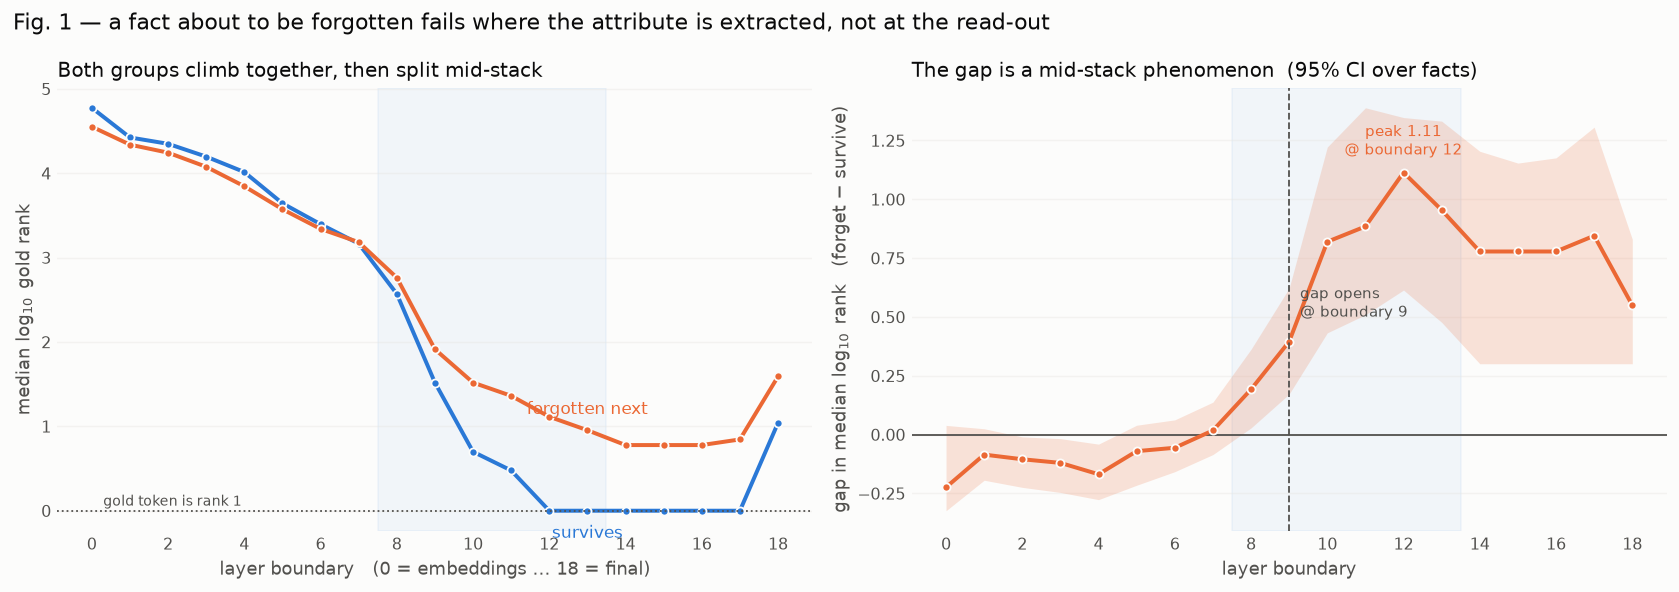

4154 transitions, forget rate 24.1%
boundary:     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
gap     : -0.22 -0.09 -0.10 -0.12 -0.17 -0.07 -0.06  0.02  0.19  0.40  0.82  0.88  1.11  0.95  0.78  0.78  0.78  0.85  0.55

median log10 gold rank at the peak (boundary 12): survive 0.00 (rank 1.0)   forget 1.11 (rank 13.0)
best the median fact ever reaches above boundary 8: survive rank 1.0 (@ 12)   forget rank 6.0 (@ 14)


In [4]:
# ── Fig. 1 — logit-lens depth profile, survive vs forget-next  (internal §8) ──────────
log_rank = np.log10(np.clip(GRL, 1, None))
cur = log_rank[XF, XT]                                   # (n_transitions, n_boundaries)
med_s, med_f = np.median(cur[~XFG], 0), np.median(cur[XFG], 0)

# bootstrap the gap over facts
rng = np.random.default_rng(0)
uf = np.unique(XF)
pos = {f: np.where(XF == f)[0] for f in uf}
boot = np.empty((300, n_bound))
for b in range(300):
    pick = rng.choice(uf, uf.size, replace=True)[:250]
    sel = np.concatenate([pos[f] for f in pick])
    boot[b] = np.median(cur[sel][XFG[sel]], 0) - np.median(cur[sel][~XFG[sel]], 0)
lo_b, hi_b = np.percentile(boot, [2.5, 97.5], axis=0)
gap = med_f - med_s

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
xl = np.arange(n_bound)
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax1.plot(xl, med_s, color=BLUE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.plot(xl, med_f, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.annotate("survives", (xl[13], med_s[13]), color=BLUE, fontsize=9.5,
             xytext=(0, -15), textcoords="offset points", ha="center")
ax1.annotate("forgotten next", (xl[13], med_f[13]), color=ORANGE, fontsize=9.5,
             xytext=(0, 9), textcoords="offset points", ha="center")
ax1.axhline(0, color=INK2, lw=1, ls=":")
ax1.text(0.3, 0.06, "gold token is rank 1", fontsize=8, color=INK2)
ax1.set_xlabel("layer boundary   (0 = embeddings … 18 = final)")
ax1.set_ylabel("median $\\log_{10}$ gold rank")
ax1.set_title("Both groups climb together, then split mid-stack", loc="left")

ax2.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax2.axhline(0, color=INK2, lw=1)
ax2.fill_between(xl, lo_b, hi_b, color=ORANGE, alpha=.18, linewidth=0)
ax2.plot(xl, gap, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
split = int(np.argmax(gap > 0.25))
peak = int(np.argmax(gap))
ax2.axvline(split, color=INK2, ls="--", lw=1)
ax2.annotate(f"gap opens\n@ boundary {split}", (split, gap.max() * .45),
             xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK2)
ax2.annotate(f"peak {gap[peak]:.2f}\n@ boundary {peak}", (peak, gap[peak]), color=ORANGE,
             fontsize=8.5, ha="center", xytext=(0, 10), textcoords="offset points")
ax2.set_xlabel("layer boundary")
ax2.set_ylabel("gap in median $\\log_{10}$ rank   (forget − survive)")
ax2.set_title("The gap is a mid-stack phenomenon  (95% CI over facts)", loc="left")

for ax in (ax1, ax2):
    ax.set_xticks(xl[::2])
    clean(ax)
fig.suptitle("Fig. 1 — a fact about to be forgotten fails where the attribute is extracted, "
             "not at the read-out", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

print(f"{XFG.size} transitions, forget rate {XFG.mean():.1%}")
print("boundary:", " ".join(f"{i:5d}" for i in xl))
print("gap     :", " ".join(f"{v:5.2f}" for v in gap))
print(f"\nmedian log10 gold rank at the peak (boundary {peak}): "
      f"survive {med_s[peak]:.2f} (rank {10**med_s[peak]:.1f})   "
      f"forget {med_f[peak]:.2f} (rank {10**med_f[peak]:.1f})")
_bs = 8 + int(np.argmin(med_s[8:]))
_bf = 8 + int(np.argmin(med_f[8:]))
print(f"best the median fact ever reaches above boundary 8: "
      f"survive rank {10**med_s[_bs]:.1f} (@ {_bs})   forget rank {10**med_f[_bf]:.1f} (@ {_bf})")

**Result.** Through boundaries 0–7 the two groups are indistinguishable — if anything the
soon-to-be-forgotten facts are *slightly ahead*. The gap opens at boundary 8 and peaks at
**boundary 12 with ≈1.1 log-units**, a full order of magnitude in gold rank: by there the
median surviving fact has the gold token at rank 1 and holds it to the top of the stack, while
the median soon-to-be-forgotten fact never gets below ≈ rank 6.

This is the shape Geva et al. (2023) predict if the failure is in **attribute extraction**
rather than in the read-out — early-layer processing of the prompt is intact, and the fact is
lost where the attribute should be pulled from the subject representation into the answer
position. It also sharpens the "no cliff" reading of the event-aligned scalars: flat *at the
output* is not flat *through depth*; the fragility is a specific mid-stack deficit that the
final-layer scalars average away.

*Suggested caption.* "Median logit-lens rank of the gold token by layer, for currently-correct
facts that survive to the next checkpoint (blue) vs. those forgotten at it (orange), pooled
over 4 154 transitions. Right: their difference, with a 95% interval bootstrapped over facts.
The two groups are indistinguishable through boundary 7 and diverge by an order of magnitude
at boundary 12. Shading marks the mid-stack band (layers 8–13) identified independently in
Fig. A1."

In [5]:
# ── the top-k active-neuron dump: per-(fact, checkpoint, layer) summaries  (internal §13) ──
# Needed by Fig. 2 and by A1/A4.  One streaming pass over the 13 checkpoints x 2 positions.
NEU_DIR = Path("data/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons")
_meta = json.loads((NEU_DIR / f"internal/neurons_step{steps[-1]}_meta.json").read_text())
K_NEU, n_mlp, MISSING = _meta["k"], _meta["n_layers"], _meta["missing_sentinel"]
N_INTER = 5632                      # LMEnt-1B intermediate_size
MID = slice(8, 14)                  # the mid-stack band Fig. 1 localised the failure to
xlayer = np.arange(n_mlp)
# NB: Fig. 1 indexes the 19 *layer boundaries* of the logit lens; the dump indexes the 18 MLP
# layers.  MLP layer l writes into boundary l+1, so Fig. 1's boundary-12 peak is MLP layer 11.

_nids = np.load(NEU_DIR / f"internal/neurons_step{steps[-1]}_ids.npy", allow_pickle=True)
NROW = pd.Index(_nids).get_indexer(ids)                 # dump row -> panel row
assert (NROW >= 0).all(), "the neuron run does not cover every fact in the panel"

def _load(step, pos, what):
    a = np.load(NEU_DIR / f"internal/neurons_step{step}_{pos}_{what}.npy", mmap_mode="r")
    return np.asarray(a[NROW])

def _pair(iA, vA, iB, vB, k):
    """|A n B| and the cosine of two sparse activation vectors over the top-k support, for
    every (fact, layer) at once.  Concatenating the two index sets and sorting puts a shared
    neuron's two copies side by side, so one pass gives both quantities -- no k x k comparison
    and no dense 5632-wide buffer."""
    A, B = iA[..., :k].astype(np.int32), iB[..., :k].astype(np.int32)
    cat = np.concatenate([A, B], -1)
    order = np.argsort(cat, axis=-1, kind="stable")
    s = np.take_along_axis(cat, order, -1)
    eq = s[..., 1:] == s[..., :-1]        # top-k indices are distinct within a set, so an
    vs = np.take_along_axis(              # adjacent equal pair == a shared neuron
        np.concatenate([vA[..., :k], vB[..., :k]], -1), order, -1)
    dot = (vs[..., 1:] * vs[..., :-1] * eq).sum(-1)
    nrm = np.sqrt((vA[..., :k] ** 2).sum(-1) * (vB[..., :k] ** 2).sum(-1))
    return eq.sum(-1), dot / np.maximum(nrm, 1e-12)

def neuron_summaries(pos):
    """(n_facts, n_steps[-lag], n_mlp) float32 summaries.

    State at a checkpoint      H   normalised entropy of the top-k |activation|s
                               PR  participation ratio -- the effective neuron count
                               L1  total top-k activation mass
                               GEN genericity: the mean share of *other panel facts* that
                                   also have this fact's top-k neurons in theirs
    Change between checkpoints COS cosine of the sparse activation vectors, t -> t+1
                               J32 Jaccard of the top-32 index sets,        t -> t+1
    """
    n = len(ids)
    o = {k: np.full((n, n_steps, n_mlp), np.nan, np.float32) for k in ("H", "PR", "L1", "GEN")}
    o.update({k: np.full((n, n_steps - 1, n_mlp), np.nan, np.float32) for k in ("COS", "J32")})
    prev = None
    for t, s in enumerate(steps):
        I, V = _load(s, pos, "idx"), _load(s, pos, "val").astype(np.float32)
        assert (I != MISSING).all(), f"step {s} {pos}: position not located for some fact"
        a = np.abs(V); tot = a.sum(-1)
        p = a / np.maximum(tot, 1e-12)[..., None]
        o["H"][:, t] = -(p * np.log(np.maximum(p, 1e-12))).sum(-1) / np.log(K_NEU)
        o["PR"][:, t] = tot ** 2 / np.maximum((V ** 2).sum(-1), 1e-12)
        o["L1"][:, t] = tot
        for l in range(n_mlp):                     # population share of each top-k neuron
            popc = np.bincount(I[:, l, :].ravel(), minlength=N_INTER).astype(np.float32)
            o["GEN"][:, t, l] = popc[I[:, l, :]].mean(-1) / n
        if prev is not None:
            _, cos = _pair(I, V, prev[0], prev[1], K_NEU)
            inter, _ = _pair(I, V, prev[0], prev[1], 32)
            o["COS"][:, t - 1] = cos
            o["J32"][:, t - 1] = inter / (64 - inter)
        prev = (I, V)
    return o

_t0 = time.time()
NA = neuron_summaries("answer")          # the token that predicts the answer
NS = neuron_summaries("subject_last")    # the subject's last token
print(f"neuron summaries in {time.time() - _t0:.0f}s: "
      f"top-{K_NEU} neurons x {n_mlp} MLP layers x 2 positions")

def within_z(M):
    """z-score each (interval, layer) column.  Consecutive checkpoints are 50k optimizer steps
    apart and the whole network moves in between, so raw similarity is dominated by *which*
    interval it is.  Standardising within the interval asks the only question that is about the
    fact: did this fact's neurons move more than its peers' did over the same 50k steps?"""
    out = np.full_like(M, np.nan)
    for t in range(M.shape[1]):
        mu, sd = np.nanmean(M[:, t], 0), np.nanstd(M[:, t], 0)
        out[:, t] = (M[:, t] - mu) / np.maximum(sd, 1e-9)
    return out

ZA_COS, ZA_J32 = within_z(NA["COS"]), within_z(NA["J32"])
ZS_COS = within_z(NS["COS"])

neuron summaries in 9s: top-128 neurons x 18 MLP layers x 2 positions


---
# Figure 2 (body) — the instability precedes the loss, and it predicts it

**Source:** `forgetting_internal_features.ipynb` §14a and §16.
**Papers:** Ramasesh et al. (2021), *Anatomy of Catastrophic Forgetting*; Geva et al. (2023);
Toneva et al. (2019).

### Why this figure

Figure 1 says *where*. This one has to carry two things the paper cannot do without.

**(a) Ante-hoc, not concurrent.** The similarity between checkpoints $t$ and $t{+}1$ **spans
the forgetting event** — using it to "predict" forgetting at $t{+}1$ is partly circular, since
the model's answer changed and so of course its state did. The panel therefore plots both: the
churn *across* the flip (dotted, descriptive) and the churn over the interval that **ended** at
the still-correct checkpoint (solid, strictly predictive — nothing in it can know about
$t{+}1$). If the solid curve separates the groups too, instability *precedes* the loss.

**(b) It is not a repackaging of "weakly stored".** The right panel is the honest test: 5-fold
cross-validation with the **fact** as the group (a fact's 12 transitions never straddle a
split), against a real baseline — not `gold_prob` alone but all four output scalars, the best
the scalar analysis had.

Every churn number is z-scored within its (interval, layer) column, for the reason given in the
`within_z` docstring above.

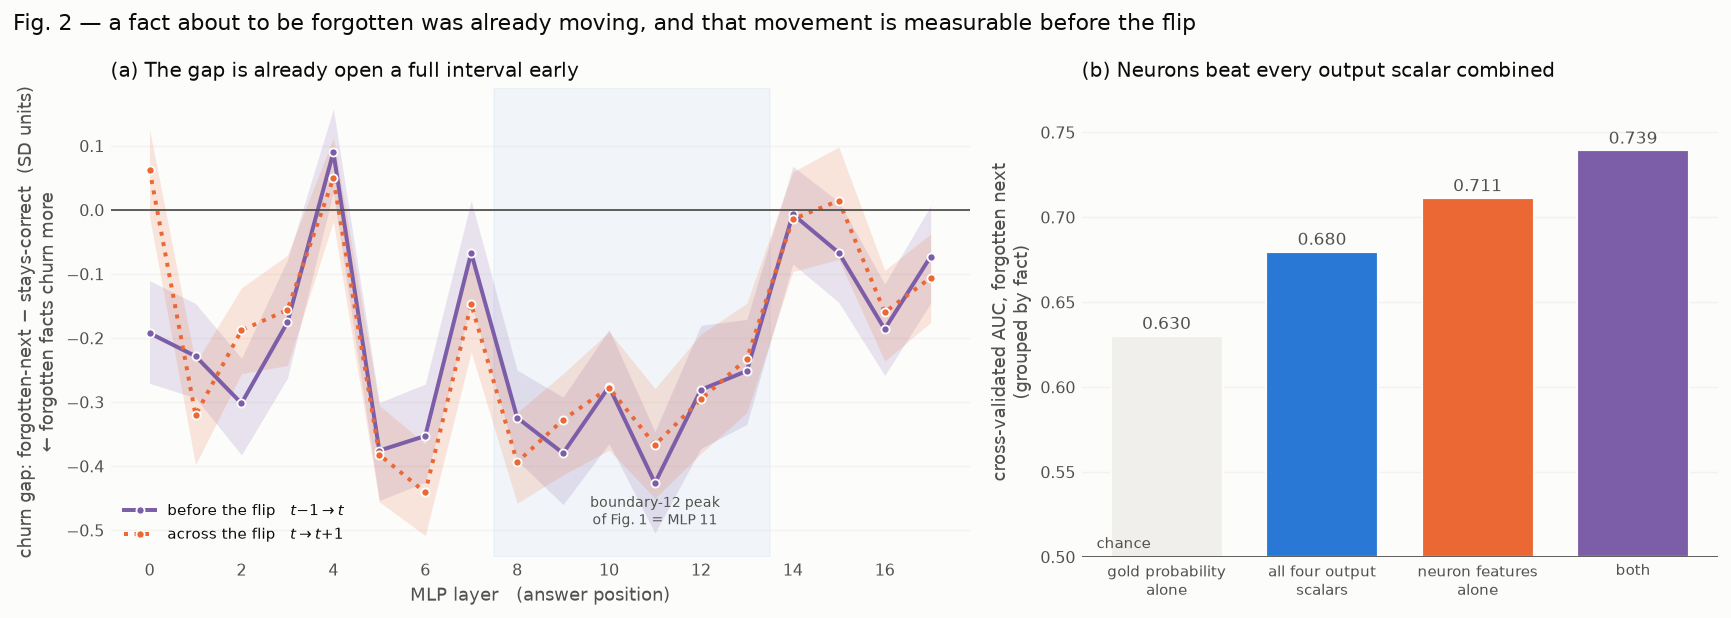

per-layer z-gap (forget − survive); negative = forgotten facts churn more
  layer       :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17
  before flip : -0.19 -0.23 -0.30 -0.18 +0.09 -0.38 -0.35 -0.07 -0.32 -0.38 -0.28 -0.43 -0.28 -0.25 -0.01 -0.07 -0.19 -0.07
  across flip : +0.06 -0.32 -0.19 -0.16 +0.05 -0.38 -0.44 -0.15 -0.39 -0.33 -0.28 -0.37 -0.30 -0.23 -0.01 +0.01 -0.16 -0.11
  95% CI      :   *      *      *      *      +      *      *      .      *      *      *      *      *      *      .      .      *      .  
mid-stack backward churn, z (higher = more stable neurons):
  forgotten next                                 n=  940   -0.044
  survives — just learned (wrong at t−1)         n=  649   +0.104
  survives — stably correct (correct at t−1)     n= 2376   +0.327
  survives — all  (the baseline plotted above)   n= 3025   +0.279
  gap vs ALL survivors            -0.323
  gap vs STABLY-CORRECT survivors -0.371   <- th

In [6]:
# ── Fig. 2a — per-layer churn gap, before vs across the flip  (internal §14a) ─────────
def churn_gap(Z, F, T, FG, lag_back=0, n_boot=300, seed=0):
    """Mean z-gap per layer (forget - survive) + a 95% CI bootstrapped over *facts*."""
    cur = Z[F, T - lag_back]
    gap = np.nanmean(cur[FG], 0) - np.nanmean(cur[~FG], 0)
    rng = np.random.default_rng(seed)
    uf = np.unique(F)
    pos = {f: np.where(F == f)[0] for f in uf}
    boot = np.empty((n_boot, Z.shape[2]))
    for b in range(n_boot):
        sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        m = FG[sel]
        boot[b] = np.nanmean(cur[sel][m], 0) - np.nanmean(cur[sel][~m], 0)
    return gap, *np.percentile(boot, [2.5, 97.5], axis=0)

# ── Fig. 2b — do the neurons say anything the output scalars do not?  (internal §16) ──
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def band(D, key, sl, back=0):
    return np.nanmean(D[key][AF, AT - back][:, sl], 1)

OUT_SCALARS = {                       # everything the scalar analysis already had
    "gold probability":   -P["gold_prob"].to_numpy()[AF, AT],
    "gold rank":           np.log10(np.clip(P["gold_rank"].to_numpy()[AF, AT], 1, None)),
    "answer margin":      -P["answer_margin"].to_numpy()[AF, AT],
    "predictive entropy":  P["pred_entropy"].to_numpy()[AF, AT],
}
NEURON_SCALARS = {                    # new, from the top-128 dump; all measured at or before t
    "churn, answer (mid)":      -np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1),
    "churn, answer (early)":    -np.nanmean(ZA_COS[AF, AT - 1][:, :8], 1),
    "churn, answer (late)":     -np.nanmean(ZA_COS[AF, AT - 1][:, 14:], 1),
    "churn, subject (mid)":     -np.nanmean(ZS_COS[AF, AT - 1][:, MID], 1),
    "top-32 churn (mid)":       -np.nanmean(ZA_J32[AF, AT - 1][:, MID], 1),
    "diffuse activation (mid)":  band(NA, "PR", MID),
    "high activation entropy":   band(NA, "H", MID),
    "private neurons (mid)":    -band(NA, "GEN", MID),
    "shared neurons (late)":     band(NA, "GEN", slice(12, 16)),
    "large activation mass":     np.log10(np.clip(band(NA, "L1", MID), 1, None)),
}
X_out = np.column_stack(list(OUT_SCALARS.values()))
X_neu = np.column_stack(list(NEURON_SCALARS.values()))

def cv_auc(X):
    X = np.nan_to_num(X, nan=0.0); oof = np.zeros(len(X))
    for tr, te in GroupKFold(n_splits=5).split(X, AFG, groups=AF):
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X[tr], AFG[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return roc_auc_score(AFG, oof)

BLOCKS = [("gold probability\nalone", X_out[:, :1], NEUTRAL),
          ("all four output\nscalars", X_out, BLUE),
          ("neuron features\nalone", X_neu, ORANGE),
          ("both", np.column_stack([X_out, X_neu]), PURPLE)]
aucs = [cv_auc(X) for _, X, _ in BLOCKS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.8),
                               gridspec_kw={"width_ratios": [1.35, 1]})
for lag, col, lab, ls in ((1, PURPLE, "before the flip   $t{-}1 \\rightarrow t$", "-"),
                          (0, ORANGE, "across the flip   $t \\rightarrow t{+}1$", ":")):
    F, T, FG = (XF, XT, XFG) if lag == 0 else (AF, AT, AFG)
    g, lo, hi = churn_gap(ZA_COS, F, T, FG, lag_back=lag)
    ax1.fill_between(xlayer, lo, hi, color=col, alpha=.16, linewidth=0)
    ax1.plot(xlayer, g, color=col, lw=2.2, ls=ls, marker="o", ms=4.5, mec=SURF, mew=1, label=lab)
ax1.axhline(0, color=INK2, lw=1)
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax1.annotate("boundary-12 peak\nof Fig. 1 = MLP 11", (11, -0.44), fontsize=8, color=INK2,
             ha="center", xytext=(0, -18), textcoords="offset points")
ax1.set_xticks(range(0, n_mlp, 2))
ax1.set_xlabel("MLP layer   (answer position)")
ax1.set_ylabel("churn gap: forgotten-next − stays-correct  (SD units)\n← forgotten facts churn more")
ax1.set_title("(a) The gap is already open a full interval early", loc="left")
ax1.legend(loc="lower left", fontsize=8.5)

ax2.bar(range(len(BLOCKS)), [a - .5 for a in aucs], bottom=.5,     # bar length = lift over chance
        color=[c for _, _, c in BLOCKS], edgecolor=SURF, linewidth=1.2, width=.72)
for i, v in enumerate(aucs):
    ax2.text(i, v + .004, f"{v:.3f}", ha="center", fontsize=9.5, color=INK2)
ax2.axhline(0.5, color=INK2, lw=1)
ax2.text(-0.45, 0.503, "chance", ha="left", va="bottom", fontsize=8.5, color=INK2)
ax2.set_xticks(range(len(BLOCKS)), [b[0] for b in BLOCKS], fontsize=8.5)
ax2.set_ylim(0.5, max(aucs) * 1.05)
ax2.set_ylabel("cross-validated AUC, forgotten next\n(grouped by fact)")
ax2.set_title("(b) Neurons beat every output scalar combined", loc="left")

for ax in (ax1, ax2):
    clean(ax)
fig.suptitle("Fig. 2 — a fact about to be forgotten was already moving, and that movement is "
             "measurable before the flip", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

g_b, lo_b2, hi_b2 = churn_gap(ZA_COS, AF, AT, AFG, lag_back=1, n_boot=200)
g_c, _, _ = churn_gap(ZA_COS, XF, XT, XFG, lag_back=0, n_boot=200)
print("per-layer z-gap (forget − survive); negative = forgotten facts churn more")
print("  layer       :", " ".join(f"{i:5d}" for i in xlayer))
print("  before flip :", " ".join(f"{v:+5.2f}" for v in g_b))
print("  across flip :", " ".join(f"{v:+5.2f}" for v in g_c))
# "*" = the whole CI is below 0 (forgotten churn more); "+" = the whole CI is ABOVE 0
# (survivors churn more -- layer 4 is the one place in the stack where that happens);
# "." = the CI spans 0.
print("  95% CI      :", "  ".join("  *  " if h < 0 else ("  +  " if l > 0 else "  .  ")
                                   for l, h in zip(lo_b2, hi_b2)))

bwd = np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1)

# Is the comparison group the right one?  Both groups are correct at t by construction, so
# "survives" already means "correct at t AND correct at t+1".  But over the *backward* window
# it silently mixes two kinds of survivor: facts that were already correct at t-1, and facts
# that were WRONG at t-1 and had just been learned -- and learning moves neurons too.  Splitting
# them shows the baseline is diluted, so the headline gap is conservative.
_was = correct[AF, AT - 1]
_grp = [("forgotten next", AFG),
        ("survives — just learned (wrong at t−1)", (~AFG) & ~_was),
        ("survives — stably correct (correct at t−1)", (~AFG) & _was),
        ("survives — all  (the baseline plotted above)", ~AFG)]
print("mid-stack backward churn, z (higher = more stable neurons):")
for nm, m in _grp:
    print(f"  {nm:46s} n={m.sum():5d}   {np.nanmean(bwd[m]):+.3f}")
print(f"  gap vs ALL survivors            {np.nanmean(bwd[AFG]) - np.nanmean(bwd[~AFG]):+.3f}")
print(f"  gap vs STABLY-CORRECT survivors {np.nanmean(bwd[AFG]) - np.nanmean(bwd[(~AFG) & _was]):+.3f}"
      f"   <- the cleaner contrast is LARGER, so the plotted gap understates the effect")

gpA = P["gold_prob"].to_numpy()[AF, AT]
gt = pd.qcut(gpA, 3, labels=False, duplicates="drop")
_w = [spearmanr(-bwd[gt == g], AFG[gt == g])[0] for g in range(3)]
_gw = [spearmanr(-gpA[gt == g], AFG[gt == g])[0] for g in range(3)]
print(f"\nrho(backward mid-stack churn, forgotten-next) = {spearmanr(-bwd, AFG)[0]:+.3f}")
print(f"  within gold-prob terciles: " + " ".join(f"{v:+.3f}" for v in _w) +
      f"   (mean {np.mean(_w):+.3f})")
print(f"  same for gold_prob itself: " + " ".join(f"{v:+.3f}" for v in _gw) +
      f"   (mean {np.mean(_gw):+.3f})")
print(f"\n{AFG.size} ante-hoc transitions from {len(np.unique(AF))} facts, base rate {AFG.mean():.1%}")
for (nm, _, _), v in zip(BLOCKS, aucs):
    print(f"  {nm.replace(chr(10), ' '):26s} CV AUC {v:.3f}")

**What panel (a) does and does not establish.** The gap is negative at 14 of 18 layers, so the
doomed facts were moving more *broadly through the stack*, not in one band. Unlike Fig. 1 —
flat through boundary 7, then a clean divergence — this curve is deep at layers 1–3 and 5–6 as
well as mid-stack. The defensible claim is therefore *"instability is diffuse, and its deepest
ante-hoc point coincides with the layer where the logit-lens failure peaks"*, **not** "churn is
localised to the mid-stack". The localisation rests on Fig. 1; panel (a) corroborates the peak,
not the localisation. One layer reverses: at **layer 4 the survivors churn significantly more**
(marked `+` in the printout) — the single place in the stack where movement is not a bad sign.

**Result.** The **backward** curve — measured over the interval that ended at the still-correct
checkpoint, so it cannot be an echo of the flip — is almost superimposed on the concurrent one,
and around MLP layer 11 it is *deeper*. Layer 11 writes into boundary 12, so **the layer where
Figure 1 finds the logit-lens gap to peak is the layer where the backward neuron churn is
largest.** Two independent measurements — one from the output projection, one from the raw
activations — put the failure in the same place.

It survives conditioning on confidence, which is what makes it more than a restatement of
"weakly stored": ranking transitions by the previous interval's churn gives ρ ≈ +0.21 with
being forgotten next, and inside gold-probability terciles the mean is ≈ +0.13 against ≈ +0.06
for `gold_prob` ranked against itself the same way.

And ten summaries of a truncated top-128 dump, with **no access to the vocabulary**, reach
CV AUC 0.711 against 0.680 for all four output scalars, adding +0.059 on top of them — more
than the three extra output scalars add to `gold_prob` (+0.050).

**Is "survives" the right comparison group?** Both groups are correct at $t$ by construction, so
the baseline already *is* "correct and stays correct" — but only in the one-step sense, and over
the backward window that quietly mixes two kinds of survivor. The printout splits them, and the
ordering is a sanity check the figure does not otherwise get credit for:

| group at $t$ (all correct) | n | mean backward mid-stack churn (z) |
|---|---|---|
| forgotten next | 940 | **−0.044** |
| survives — just learned (wrong at $t{-}1$) | 649 | +0.104 |
| survives — stably correct (correct at $t{-}1$) | 2 376 | **+0.327** |

Churn tracks state *change in either direction*: facts that had just been **learned** sit
between the stably-correct and the doomed, because acquiring a fact moves its neurons too. That
is what a measure of genuine representational movement should do, and it means the plotted
baseline is **diluted** — against stably-correct survivors alone the gap widens from −0.323 to
**−0.371**. The headline number is therefore conservative. The one-step baseline is kept in the
figure because it is the same population Fig. 2b is scored on, which keeps the two panels
comparable; the stricter contrast belongs in the text.

**Two things to concede in the text.** The absolute numbers are modest (0.739 on a 23.7% base
rate is useful ranking, not a reliable alarm), and part of the block gain is ten features
against four — though the comparison is cross-validated with the fact as the group, so it is
not overfitting in the ordinary sense. The effect is also concentrated in the low-confidence
band: churn tells you which of the *marginal* facts will go, and adds little among facts the
model holds confidently.

In [7]:
# ── the hidden-state run: final-layer residuals + cross-fitted per-layer separability ──
# One streaming pass; the (1452, 19, 2048) tensors never co-reside.  Feeds Fig. 3 and A2/A3.
from sklearn.model_selection import cross_val_predict, KFold, LeaveOneGroupOut

HBASE = "data/artifacts/expermints/15shot_trajectory_top10_internal_with_hidden"
def index_by_step(pattern):          # files carry browser-download suffixes like " (1)"
    out = {}
    for f in glob.glob(pattern):
        m = re.search(r"step(\d+)", os.path.basename(f))
        if m:
            out[int(m.group(1))] = f
    return out

h_rec_files = index_by_step(f"{HBASE}/recall/*.parquet")
h_ans_files = index_by_step(f"{HBASE}/internal/hidden_step*_answer*.npy")
h_subj_files = index_by_step(f"{HBASE}/internal/hidden_step*_subject_last*.npy")
h_id_files = index_by_step(f"{HBASE}/internal/hidden_step*_ids*.npy")
STEPS = sorted(h_rec_files)
assert set(STEPS) == set(h_ans_files) == set(h_subj_files) == set(h_id_files)

IDS = np.load(h_id_files[STEPS[0]], allow_pickle=True)
recall = {s: pd.read_parquet(h_rec_files[s]) for s in STEPS}
for s in STEPS:
    assert (np.load(h_id_files[s], allow_pickle=True) == IDS).all()
    assert (recall[s]["id"].to_numpy() == IDS).all()
n_f, n_t = len(IDS), len(STEPS)

h_correct = np.column_stack([recall[s]["correct"].to_numpy().astype(bool) for s in STEPS])
scoreable = ~recall[STEPS[0]]["excluded"].to_numpy().astype(bool)
h_prop = (pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv")
          .set_index("id").loc[IDS]["prop"].to_numpy())

def feat_matrix(col):                # (n_steps, n_facts), matching the drift/margin indexing
    return np.column_stack([pd.to_numeric(recall[s][col], errors="coerce").to_numpy()
                            for s in STEPS]).astype(float).T
h_gold_prob = feat_matrix("gold_prob")
h_answer_margin = feat_matrix("answer_margin")
h_resid_norm = feat_matrix("resid_norm_last")

def stack_layered(col):              # (n_steps, n_facts, n_layers)
    return np.stack([np.stack(recall[s][col].to_numpy()).astype(float) for s in STEPS])
act_ans = stack_layered("mlp_active_frac_by_layer")
part_ans = stack_layered("mlp_participation_by_layer")

TR_FACT, TR_T, TR_FORGET = [], [], []
for t in range(n_t - 1):
    idx = np.where(scoreable & h_correct[:, t])[0]
    TR_FACT.append(idx); TR_T.append(np.full(idx.size, t)); TR_FORGET.append(~h_correct[idx, t + 1])
TR_FACT, TR_T = np.concatenate(TR_FACT), np.concatenate(TR_T)
TR_FORGET = np.concatenate(TR_FORGET).astype(bool)

FOLD = np.random.default_rng(0).integers(0, 5, size=n_f)    # fact-level folds, fixed everywhere

def nc_auc_xfit(X, y, fold):
    """Nearest-centroid separability with centroids fit on the *other* folds."""
    if y.sum() < 10 or (~y).sum() < 10:
        return np.nan
    score = np.full(len(y), np.nan)
    for f in range(5):
        te, tr = fold == f, fold != f
        if not (y[tr].any() and (~y[tr]).any() and te.any()):
            continue
        mu_c, mu_w = X[tr & y].mean(0), X[tr & ~y].mean(0)
        score[te] = (np.linalg.norm(X[te] - mu_w, axis=1) - np.linalg.norm(X[te] - mu_c, axis=1))
    m = ~np.isnan(score)
    return roc_auc_score(y[m], score[m]) if 0 < y[m].mean() < 1 else np.nan

L_FINAL = 18
Hf_ans = np.empty((n_t, n_f, 2048), np.float32)
Hf_subj = np.empty((n_t, n_f, 2048), np.float32)
sep_xf_ans = np.full((n_t, 19), np.nan)
sep_xf_subj = np.full((n_t, 19), np.nan)

_t0 = time.time()
for ti, s in enumerate(STEPS):
    A = np.load(h_ans_files[s]).astype(np.float32)     # (n_facts, 19, 2048)
    S = np.load(h_subj_files[s]).astype(np.float32)
    Hf_ans[ti], Hf_subj[ti] = A[:, L_FINAL, :], S[:, L_FINAL, :]
    y, fo = h_correct[scoreable, ti], FOLD[scoreable]
    for L in range(19):
        sep_xf_ans[ti, L] = nc_auc_xfit(A[scoreable, L], y, fo)
        sep_xf_subj[ti, L] = nc_auc_xfit(S[scoreable, L], y, fo)
    del A, S
print(f"hidden states streamed in {time.time() - _t0:.0f}s")
print(f"{n_f} facts x {n_t} checkpoints | {scoreable.sum()} scoreable | "
      f"{TR_FORGET.size} correct->next transitions ({TR_FORGET.mean():.1%} forgotten)")
print("(this run is a separate evaluation pass from the panel above, so the transition count "
      "differs by a handful through greedy-decode noise)")

hidden states streamed in 25s
1452 facts x 13 checkpoints | 1310 scoreable | 4163 correct->next transitions (24.2% forgotten)
(this run is a separate evaluation pass from the panel above, so the transition count differs by a handful through greedy-decode noise)


---
# Figure 3 (body) — half of what the model stops saying, it has not stopped representing

**Source:** `hidden_states_forgetting.ipynb` §12 (left) and
`forgetting_internal_features.ipynb` §9 (right).
**Papers:** Davari et al. (2022), *Probing Representation Forgetting* (CVPR); Kotha et al.
(2024), *Understanding Catastrophic Forgetting via Implicit Inference* (ICLR); Chang et al.
(2024).

### Why this figure

Figures 1–2 establish *where* and *when*. This one attacks *what kind of event a flip is*, and
it is the figure that most changes how the result should be described.

**(a) Read-out or storage?** The natural way to ask is with `is_top1` and `resolution_depth` —
but both are functions of the output distribution, so they cannot separate the two. Davari
et al.'s design can: freeze the representation, fit a **linear probe** (cross-fitted over
facts, so a fact never helps score itself), and apply it to the same facts **after** the flip.
Observed recall for that group at $t{+}1$ is 0% by construction. Whatever the probe still
recovers is information that survived the event.

**(b) Decay or takeover?** Two mechanisms produce the same binary `correct → wrong`.
*Diffusion*: the whole answer distribution flattens — gold probability falls, top-1 probability
falls too, entropy **rises**. *Takeover*: a specific competitor is promoted — gold falls while
top-1 **rises** and entropy **falls**. The first is the "the memory faded" story Chang et al.
fit decay curves to; the second is the mechanism Kotha et al. argue underlies much of what gets
called catastrophic forgetting. They are separable with two columns already extracted.

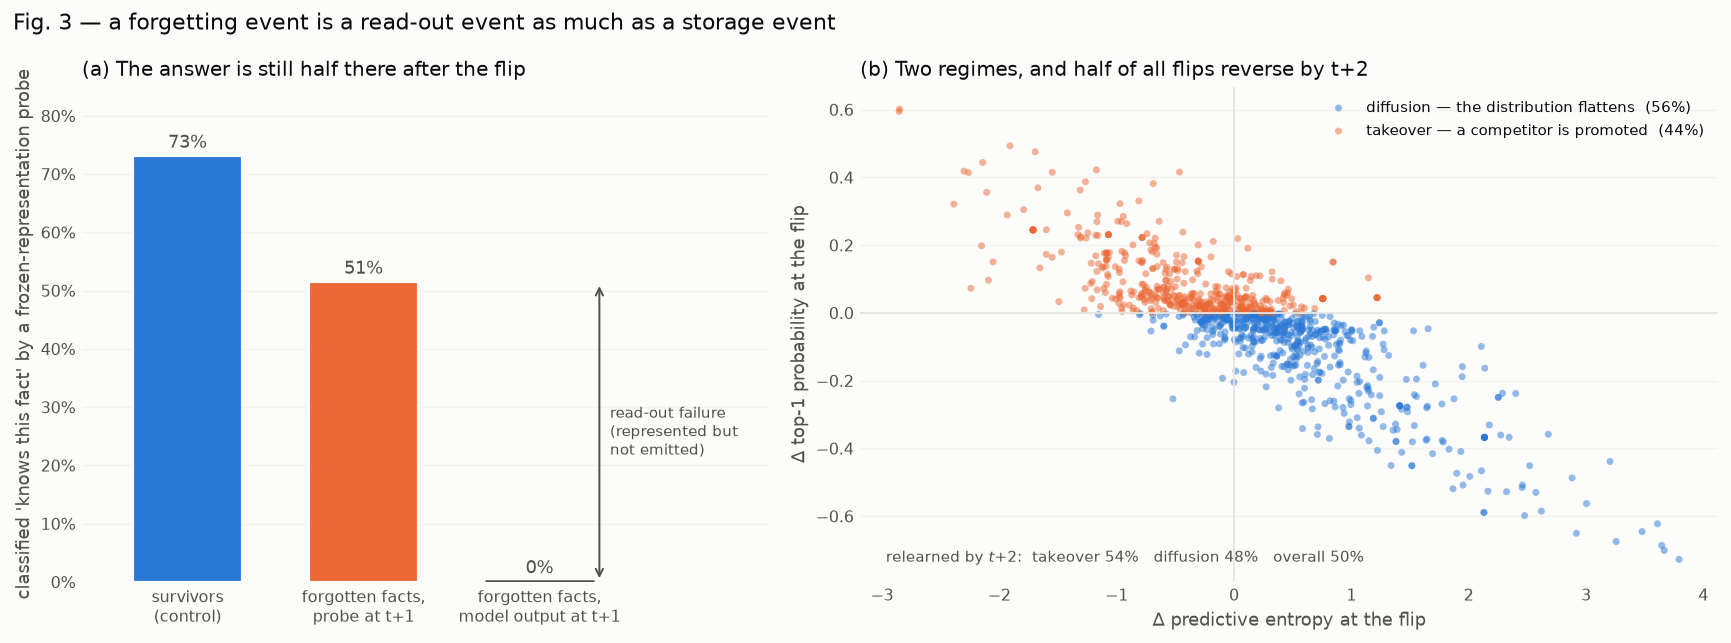

n forgotten = 1006, n survivors = 3157
  forgotten facts still classified 'known' at t+1 : 51.4%
  survivors (control)                            : 73.0%
  observed recall of the forgotten group at t+1   : 0.0%

1003 forgetting events
  takeover  (top-1 rises): 44.2%  median dtop1=+0.0502  dentropy=-0.420
  diffusion (top-1 falls): 55.8%  median dtop1=-0.0656  dentropy=+0.461
  overall median dentropy at the flip: +0.101  (> 0 => net flattening)
  relearned by t+2: overall 50.3% | takeover 53.5% vs diffusion 47.8%


In [8]:
# ── Fig. 3a — representation forgetting vs observed forgetting  (hidden §12) ──────────
still_known, ctrl_known = [], []
for t in range(n_t - 1):
    for f in range(5):
        tr = scoreable & (FOLD != f)
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[t][tr], h_correct[tr, t])
        held = scoreable & (FOLD == f) & h_correct[:, t]
        ev, sv = held & ~h_correct[:, t + 1], held & h_correct[:, t + 1]
        if ev.any():
            still_known.append(c.predict(Hf_ans[t + 1][ev]))
        if sv.any():
            ctrl_known.append(c.predict(Hf_ans[t + 1][sv]))
still_known, ctrl_known = np.concatenate(still_known), np.concatenate(ctrl_known)

# ── Fig. 3b — decay vs takeover at the flip  (internal §9) ────────────────────────────
ev_f, ev_t = np.where(correct[:, :-1] & ~correct[:, 1:])
d_top1 = NEWP["top1_prob"][ev_f, ev_t + 1] - NEWP["top1_prob"][ev_f, ev_t]
d_ent = NEWP["pred_entropy"][ev_f, ev_t + 1] - NEWP["pred_entropy"][ev_f, ev_t]
takeover = d_top1 > 0
back = np.array([correct[f, t + 2] if t + 2 < n_steps else np.nan
                 for f, t in zip(ev_f, ev_t)], float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 5.0),
                               gridspec_kw={"width_ratios": [1, 1.25]})
bars = [("survivors\n(control)", ctrl_known.mean(), BLUE),
        ("forgotten facts,\nprobe at t+1", still_known.mean(), ORANGE),
        ("forgotten facts,\nmodel output at t+1", 0.0, NEUTRAL)]
ax1.bar([b[0] for b in bars], [b[1] for b in bars],
        color=[b[2] for b in bars], edgecolor=SURF, linewidth=1.2, width=.62)
for i, b in enumerate(bars):
    ax1.text(i, b[1] + .015, f"{b[1]:.0%}", ha="center", fontsize=10, color=INK2)
ax1.plot([2 - .31, 2 + .31], [0, 0], color=INK2, lw=2.5, solid_capstyle="butt")  # 0% is a real category
ax1.annotate("", xy=(2.34, 0), xytext=(2.34, still_known.mean()),
             arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.1))
ax1.text(2.40, still_known.mean() / 2, "read-out failure\n(represented but\nnot emitted)",
         ha="left", va="center", fontsize=8.5, color=INK2)
ax1.set_xlim(-0.6, 3.3); ax1.set_ylim(0, .85)
ax1.yaxis.set_major_formatter(PCT)
ax1.set_ylabel("classified 'knows this fact' by a frozen-representation probe")
ax1.set_title("(a) The answer is still half there after the flip", loc="left")

ax2.axhline(0, color=GRID, lw=1); ax2.axvline(0, color=GRID, lw=1)
ax2.scatter(d_ent[~takeover], d_top1[~takeover], s=15, color=BLUE, alpha=.5, edgecolor="none",
            label=f"diffusion — the distribution flattens  ({(~takeover).mean():.0%})")
ax2.scatter(d_ent[takeover], d_top1[takeover], s=15, color=ORANGE, alpha=.5, edgecolor="none",
            label=f"takeover — a competitor is promoted  ({takeover.mean():.0%})")
ax2.set_xlabel("Δ predictive entropy at the flip")
ax2.set_ylabel("Δ top-1 probability at the flip")
ax2.set_title("(b) Two regimes, and half of all flips reverse by t+2", loc="left")
ax2.legend(loc="upper right", fontsize=8.5)
ax2.annotate(f"relearned by $t{{+}}2$:  takeover {np.nanmean(back[takeover]):.0%}   "
             f"diffusion {np.nanmean(back[~takeover]):.0%}   overall {np.nanmean(back):.0%}",
             (0.03, 0.04), xycoords="axes fraction", fontsize=8.5, color=INK2)

for ax in (ax1, ax2):
    clean(ax)
fig.suptitle("Fig. 3 — a forgetting event is a read-out event as much as a storage event",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

print(f"n forgotten = {still_known.size}, n survivors = {ctrl_known.size}")
print(f"  forgotten facts still classified 'known' at t+1 : {still_known.mean():.1%}")
print(f"  survivors (control)                            : {ctrl_known.mean():.1%}")
print(f"  observed recall of the forgotten group at t+1   : 0.0%")
print(f"\n{len(ev_f)} forgetting events")
print(f"  takeover  (top-1 rises): {takeover.mean():5.1%}  median dtop1={np.median(d_top1[takeover]):+.4f}"
      f"  dentropy={np.median(d_ent[takeover]):+.3f}")
print(f"  diffusion (top-1 falls): {(~takeover).mean():5.1%}  median dtop1={np.median(d_top1[~takeover]):+.4f}"
      f"  dentropy={np.median(d_ent[~takeover]):+.3f}")
print(f"  overall median dentropy at the flip: {np.median(d_ent):+.3f}  (> 0 => net flattening)")
print(f"  relearned by t+2: overall {np.nanmean(back):.1%} | takeover {np.nanmean(back[takeover]):.1%}"
      f" vs diffusion {np.nanmean(back[~takeover]):.1%}")

**Result.** Immediately after the flip a linear probe on the frozen representation still calls
**≈51%** of the forgotten facts "known", against **≈73%** for survivors and **0%** observed
recall. Representation forgetting is real — 51% is below the 73% control, so the representation
genuinely degrades — but it is roughly **half** of the observed forgetting. This is a clean
replication of Davari et al. on facts, and it is the properly-controlled version of the
`is_top1` / `resolution_depth` argument.

The right panel splits the events by mechanism: **44% are takeovers** (top-1 probability rises
by a median +0.05 while entropy *falls* 0.42 nats — a specific competitor is promoted) and
**56% are diffusion** (top-1 falls, entropy rises 0.46 nats). The aggregate entropy change is
mildly positive, so averaging the two regimes reads as "flattening" and hides that nearly half
of all forgetting is Kotha-style competition rather than decay. The regime does **not** predict
recovery: ≈54% of takeovers and ≈48% of diffusion events are correct again two checkpoints
later. That half of all forgetting events reverse within one checkpoint is itself the
headline — this is oscillation around a threshold far more than it is erasure.

**Two caveats for the caption.** The probe's own ceiling is the 73% control, not 100%, so the
comparison is 51% vs 73%. And Figure A3 shows a substantial part of the probe's signal is
entity/relation identity, which does not change between adjacent checkpoints — so 51% is an
**upper bound** on how much fact-specific knowledge survives. The direction is safe; the exact
figure is not.

---
---
# Appendix figures

## Figure A1 — the layer geography of a fact's neurons

**Source:** `forgetting_internal_features.ipynb` §13.
**Papers:** Geva et al. (2021), *FFN Layers Are Key-Value Memories*; Dai et al. (2022),
*Knowledge Neurons*; Gurnee et al. (2023), *Finding Neurons in a Haystack*; Elhage et al.
(2022), *Toy Models of Superposition*.

**Why the appendix.** Figures 1 and 2 both shade "layers 8–13" and call it the mid-stack. That
band has to be *derived* somewhere rather than asserted, and the derivation is descriptive
enough that it does not earn a body slot. Three properties per layer, at both token positions:

- **participation ratio** $(\sum|a|)^2 / \sum a^2$ — the *effective* number of neurons carrying
  the activation. Low = a few units dominate.
- **genericity** — the average share of the other 1 309 facts that also have this fact's top-128
  neurons in *their* top-128. High = the fact rides on units everybody uses; low = the units are
  close to private to it. This is the observable superposition axis, measured over facts rather
  than tokens.
- **stability** — the cosine between consecutive checkpoints' sparse activation vectors.

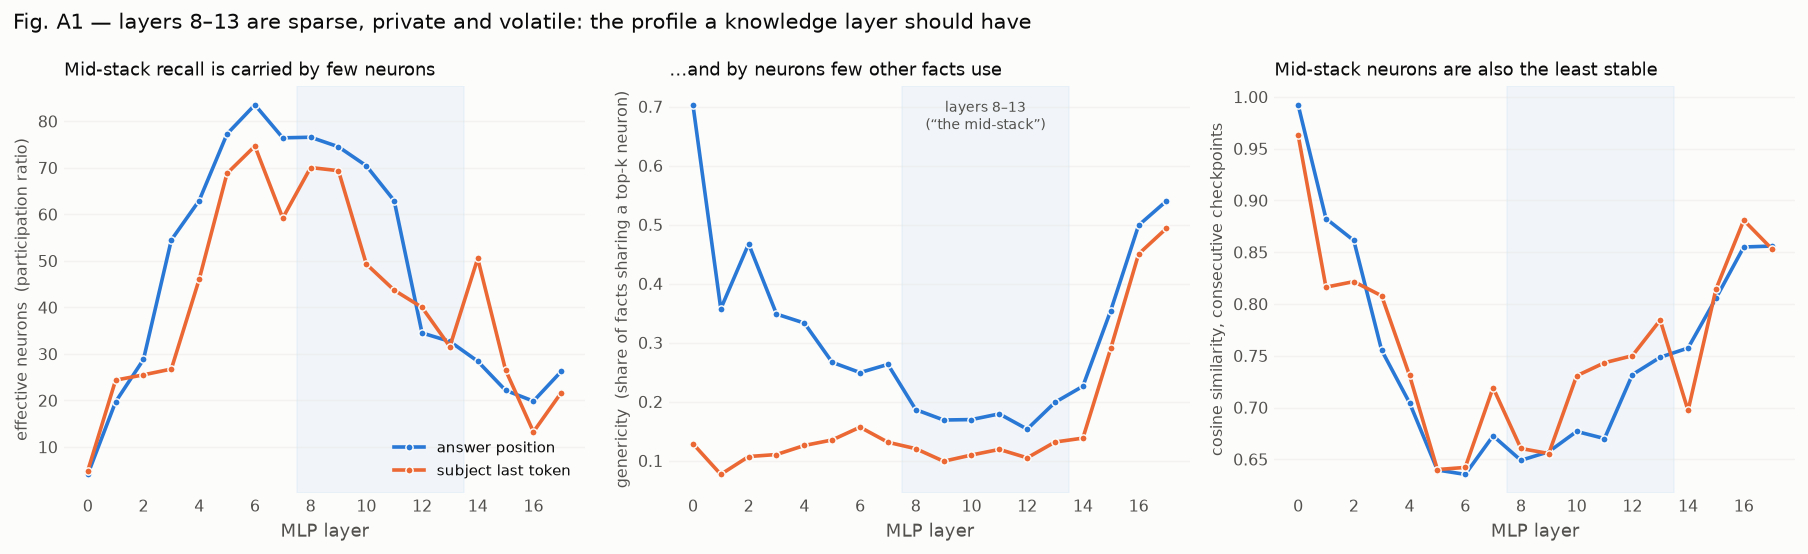

layer  PR(ans)  GEN(ans)  cos(ans)  PR(subj)  cos(subj)
    0      4.1     0.703     0.992       4.9      0.963
    1     19.7     0.357     0.882      24.4      0.816
    2     28.8     0.467     0.861      25.5      0.822
    3     54.5     0.348     0.755      26.7      0.808
    4     63.0     0.333     0.705      46.0      0.731
    5     77.3     0.267     0.640      68.8      0.640
    6     83.5     0.249     0.635      74.7      0.642
    7     76.4     0.263     0.673      59.2      0.719
    8     76.6     0.187     0.649      70.0      0.660
    9     74.5     0.169     0.657      69.4      0.656
   10     70.4     0.170     0.677      49.3      0.731
   11     62.9     0.179     0.670      43.7      0.743
   12     34.5     0.153     0.732      40.0      0.750
   13     32.7     0.199     0.749      31.6      0.784
   14     28.4     0.226     0.757      50.5      0.697
   15     22.2     0.354     0.805      26.5      0.814
   16     19.9     0.499     0.855      13.3    

In [9]:
# ── Fig. A1 — where the top-128 neurons live  (internal §13) ──────────────────────────
PANELS = [("PR",  "effective neurons  (participation ratio)",
           "Mid-stack recall is carried by few neurons"),
          ("GEN", "genericity  (share of facts sharing a top-k neuron)",
           "…and by neurons few other facts use"),
          ("COS", "cosine similarity, consecutive checkpoints",
           "Mid-stack neurons are also the least stable")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (key, ylab, title) in zip(axes, PANELS):
    for D, col, name in ((NA, BLUE, "answer position"), (NS, ORANGE, "subject last token")):
        y = np.nanmedian(D[key].reshape(-1, n_mlp), 0)
        ax.plot(xlayer, y, color=col, lw=2, marker="o", ms=4, mec=SURF, mew=.8, label=name)
    ax.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
    ax.set_xticks(range(0, n_mlp, 2))
    ax.set_xlabel("MLP layer")
    ax.set_ylabel(ylab, fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    clean(ax)
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].text(10.5, axes[1].get_ylim()[1] * .97, "layers 8–13\n(“the mid-stack”)",
             fontsize=8, color=INK2, ha="center", va="top")
fig.suptitle("Fig. A1 — layers 8–13 are sparse, private and volatile: the profile a knowledge "
             "layer should have", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"{'layer':>5s} {'PR(ans)':>8s} {'GEN(ans)':>9s} {'cos(ans)':>9s} {'PR(subj)':>9s} {'cos(subj)':>10s}")
for l in range(n_mlp):
    print(f"{l:5d} {np.nanmedian(NA['PR'][:,:,l]):8.1f} {np.nanmedian(NA['GEN'][:,:,l]):9.3f} "
          f"{np.nanmedian(NA['COS'][:,:,l]):9.3f} {np.nanmedian(NS['PR'][:,:,l]):9.1f} "
          f"{np.nanmedian(NS['COS'][:,:,l]):10.3f}")

**Result.** All three panels agree on a three-part stack. Layers 0–2 and 15–17 are *generic and
stable* — a third to two-thirds of all facts share a top-128 neuron there, and consecutive
checkpoints agree at cosine 0.81–0.99. These are format/vocabulary layers, not fact storage.
Layers 3–7 are where the activation is most **spread** (participation peaks near 84 effective
neurons at layer 6). Then layers 8–13 concentrate sharply — from ≈77 effective neurons at layer
8 down to ≈35 at layer 12 — while genericity bottoms out at ≈0.15, its minimum anywhere in the
stack, and stability is at its lowest.

Sparse, private and volatile is exactly the profile a knowledge layer should have under Geva
et al. (2021) / Dai et al. (2022), and it lands on the band Figure 1 identified independently
from the logit lens. That convergence is the reason the band can be treated as a unit in the
body figures.

---
## Figure A2 — a cross-validation audit that overturns a conclusion

**Source:** `hidden_states_forgetting.ipynb` §8.
**Papers:** Hewitt & Liang (2019), *Designing and Interpreting Probes with Control Tasks*;
Timkey & van Schijndel (2021), *All Bark and No Bite: Rogue Dimensions*.

**Why the appendix.** An earlier draft of this analysis concluded that the raw 2048-d residual
vector is "essentially non-predictive (AUC ≈ 0.48)" of which correct facts slip, and built a
headline on it: *fragility is a boundary distance, not a direction.* That rests entirely on one
line — `cross_val_predict(clf, X, y, cv=5)`. An integer `cv` means **`KFold` without shuffling**,
and the transition rows are built by looping over checkpoints, so they arrive **sorted by
training time**. Unshuffled 5-fold therefore holds out a contiguous block of checkpoints. Since
the forgetting base rate swings from 13% to 48% across checkpoints and the residual stream
drifts substantially between them, a 2048-d model fit on early checkpoints extrapolates badly
while a 1-d scalar barely notices. The 0.48 measured a distribution shift.

There is a real problem hiding underneath that cuts the other way: with *random* folds a
high-dimensional probe can identify **which checkpoint** a vector came from and just predict
that checkpoint's base rate. So neither scheme is trustworthy, and four are compared:

| scheme | leakage risk |
|---|---|
| unshuffled `KFold` (the original) | none, but confounded by checkpoint distribution shift |
| random `KFold(shuffle=True)` | one fact appears in ≤ 12 rows → **fact leakage** |
| `GroupKFold` by fact id | fixes fact leakage; **checkpoint base rate still leaks** |
| **within-checkpoint** (leave-one-checkpoint-out fit, AUC scored *inside* each checkpoint, averaged) | neither — the honest number |

Three controls the original bar chart lacked are added: `resid_norm_last` alone (is the
"geometry" just vector length?), a **whitened** margin with the top 3 principal components
removed, and a **cross-fitted** margin whose centroids exclude the scored fact.

audit in 19s


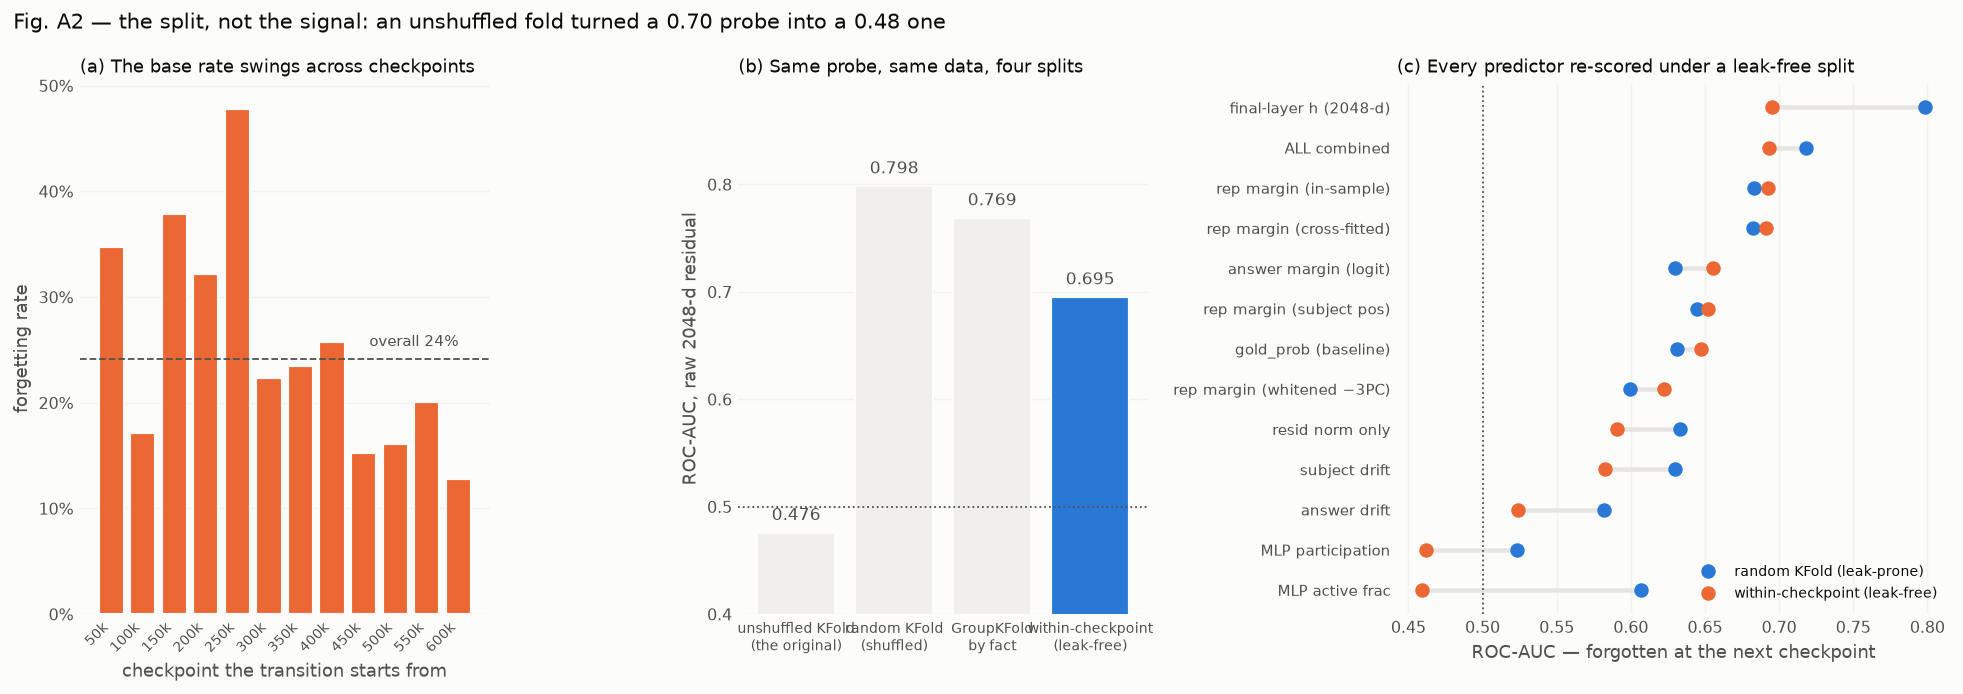

rows sorted by checkpoint? True -> unshuffled KFold splits by training time
rep_margin in-sample vs cross-fitted: r = 0.9981

feature                         orig KFold   randCV  groupCV  within-ckpt
final-layer h (2048-d)               0.476    0.798    0.769        0.695
ALL combined                         0.607    0.718    0.717        0.693
rep margin (in-sample)               0.679    0.683    0.684        0.692
rep margin (cross-fitted)            0.678    0.682    0.683        0.691
answer margin (logit)                0.625    0.630    0.629        0.655
rep margin (subject pos)             0.642    0.644    0.645        0.652
gold_prob (baseline)                 0.622    0.631    0.628        0.647
rep margin (whitened −3PC)           0.597    0.599    0.601        0.623
resid norm only                      0.587    0.633    0.634        0.591
subject drift                        0.604    0.630    0.632        0.583
answer drift                         0.568    0.582    0.584

In [10]:
# ── Fig. A2 — the CV audit  (hidden §8) ──────────────────────────────────────────────
def cos_drift(H):
    Hn = H / (np.linalg.norm(H, axis=2, keepdims=True) + 1e-8)
    return 1.0 - np.einsum("tfd,tfd->tf", Hn[:-1], Hn[1:])
drift_ans, drift_subj = cos_drift(Hf_ans), cos_drift(Hf_subj)

def _xfit_margin(H_all):
    """Nearest-centroid margin whose centroids are built WITHOUT the scored fact."""
    out = np.full((n_t, n_f), np.nan)
    for ti in range(n_t):
        H = H_all[ti]
        for f in range(5):
            te, tr = FOLD == f, (FOLD != f) & scoreable
            mu_c, mu_w = H[tr & h_correct[:, ti]].mean(0), H[tr & ~h_correct[:, ti]].mean(0)
            out[ti, te] = (np.linalg.norm(H[te] - mu_w, axis=1)
                           - np.linalg.norm(H[te] - mu_c, axis=1))
    return out

rep_margin = np.full((n_t, n_f), np.nan)                 # the in-sample version, for comparison
for ti in range(n_t):
    y, w = h_correct[:, ti] & scoreable, (~h_correct[:, ti]) & scoreable
    mu_c, mu_w = Hf_ans[ti][y].mean(0), Hf_ans[ti][w].mean(0)
    rep_margin[ti] = (np.linalg.norm(Hf_ans[ti] - mu_w, axis=1)
                      - np.linalg.norm(Hf_ans[ti] - mu_c, axis=1))
rep_margin_xf = _xfit_margin(Hf_ans)
rep_margin_subj = _xfit_margin(Hf_subj)

rep_margin_wh = np.full((n_t, n_f), np.nan)              # standardise dims, project out top-3 PCs
for ti in range(n_t):
    H = Hf_ans[ti]
    mu, sd = H[scoreable].mean(0), H[scoreable].std(0) + 1e-6
    Hw = (H - mu) / sd
    Hs = Hw[scoreable]
    V = np.linalg.svd(Hs - Hs.mean(0), full_matrices=False)[2][:3]
    Hp = Hw - (Hw @ V.T) @ V
    for f in range(5):
        te, tr = FOLD == f, (FOLD != f) & scoreable
        mu_c, mu_w = Hp[tr & h_correct[:, ti]].mean(0), Hp[tr & ~h_correct[:, ti]].mean(0)
        rep_margin_wh[ti, te] = (np.linalg.norm(Hp[te] - mu_w, axis=1)
                                 - np.linalg.norm(Hp[te] - mu_c, axis=1))

NW_FEATS = {
    "gold_prob (baseline)":       h_gold_prob[TR_T, TR_FACT],
    "answer margin (logit)":      h_answer_margin[TR_T, TR_FACT],
    "answer drift":               drift_ans[TR_T, TR_FACT],
    "subject drift":              drift_subj[TR_T, TR_FACT],
    "rep margin (in-sample)":     rep_margin[TR_T, TR_FACT],
    "rep margin (cross-fitted)":  rep_margin_xf[TR_T, TR_FACT],
    "rep margin (whitened −3PC)": rep_margin_wh[TR_T, TR_FACT],
    "rep margin (subject pos)":   rep_margin_subj[TR_T, TR_FACT],
    "resid norm only":            h_resid_norm[TR_T, TR_FACT],
    "MLP active frac":            np.nanmean(act_ans, 2)[TR_T, TR_FACT],
    "MLP participation":          np.nanmean(part_ans, 2)[TR_T, TR_FACT],
}
NW_X = np.column_stack(list(NW_FEATS.values()))
NW_OK = np.isfinite(NW_X).all(1)
NW_X, NW_Y = NW_X[NW_OK], TR_FORGET.astype(int)[NW_OK]
NW_G, NW_TT = TR_FACT[NW_OK], TR_T[NW_OK]
NW_H = Hf_ans[TR_T, TR_FACT][NW_OK]

def _score(Xc, cv, groups=None):
    Xc = Xc.reshape(len(Xc), -1)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return cross_val_predict(clf, Xc, NW_Y, cv=cv, groups=groups, method="predict_proba")[:, 1]

def four_schemes(Xc):
    a = roc_auc_score(NW_Y, _score(Xc, 5))                                    # the original
    b = roc_auc_score(NW_Y, _score(Xc, KFold(5, shuffle=True, random_state=0)))
    c = roc_auc_score(NW_Y, _score(Xc, GroupKFold(5), NW_G))
    p = _score(Xc, LeaveOneGroupOut(), NW_TT)
    w = np.nanmean([roc_auc_score(NW_Y[NW_TT == t], p[NW_TT == t])
                    for t in range(n_t - 1) if 0 < NW_Y[NW_TT == t].mean() < 1])
    return a, b, c, w

_t0 = time.time()
AUDIT = {k: four_schemes(NW_X[:, [i]]) for i, k in enumerate(NW_FEATS)}
AUDIT["ALL combined"] = four_schemes(NW_X)
AUDIT["final-layer h (2048-d)"] = four_schemes(NW_H)
print(f"audit in {time.time() - _t0:.0f}s")

rate_by_ckpt = np.array([TR_FORGET[TR_T == t].mean() for t in range(n_t - 1)])
fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(15.2, 5.4),
                                    gridspec_kw={"width_ratios": [1, 1, 1.35]})
axA.bar(range(n_t - 1), rate_by_ckpt, color=ORANGE, edgecolor=SURF, linewidth=1.2)
axA.axhline(TR_FORGET.mean(), color=INK2, ls="--", lw=1)
axA.text(n_t - 2, TR_FORGET.mean() + .012, f"overall {TR_FORGET.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
axA.set_xticks(range(n_t - 1), [f"{STEPS[t]//1000}k" for t in range(n_t - 1)],
               rotation=45, ha="right", fontsize=8)
axA.yaxis.set_major_formatter(PCT)
axA.set_xlabel("checkpoint the transition starts from")
axA.set_ylabel("forgetting rate")
axA.set_title("(a) The base rate swings across checkpoints", loc="left", fontsize=10)

schemes = ["unshuffled KFold\n(the original)", "random KFold\n(shuffled)",
           "GroupKFold\nby fact", "within-checkpoint\n(leak-free)"]
vals = AUDIT["final-layer h (2048-d)"]
axB.bar(range(4), vals, color=[NEUTRAL, NEUTRAL, NEUTRAL, BLUE], edgecolor=SURF, linewidth=1.2)
axB.axhline(0.5, color=INK2, ls=":", lw=1)
for i, v in enumerate(vals):
    axB.text(i, v + .012, f"{v:.3f}", ha="center", fontsize=9.5, color=INK2)
axB.set_xticks(range(4), schemes, fontsize=8)
axB.set_ylim(0.4, max(vals) * 1.12)
axB.set_ylabel("ROC-AUC, raw 2048-d residual")
axB.set_title("(b) Same probe, same data, four splits", loc="left", fontsize=10)

order = sorted(AUDIT, key=lambda k: AUDIT[k][3])
for i, k in enumerate(order):
    lo_, hi_ = AUDIT[k][1], AUDIT[k][3]
    axC.plot([lo_, hi_], [i, i], color=GRID, lw=2.5, zorder=1, solid_capstyle="round")
    axC.plot(lo_, i, "o", color=BLUE, ms=7, zorder=2,
             label="random KFold (leak-prone)" if i == 0 else None)
    axC.plot(hi_, i, "o", color=ORANGE, ms=7, zorder=3,
             label="within-checkpoint (leak-free)" if i == 0 else None)
axC.axvline(0.5, color=INK2, ls=":", lw=1)
axC.set_yticks(range(len(order)), order, fontsize=8.5)
axC.set_xlabel("ROC-AUC — forgotten at the next checkpoint")
axC.set_title("(c) Every predictor re-scored under a leak-free split", loc="left", fontsize=10)
axC.legend(loc="lower right", fontsize=8)

clean(axA); clean(axB); clean(axC, axis="x")
fig.suptitle("Fig. A2 — the split, not the signal: an unshuffled fold turned a 0.70 probe into "
             "a 0.48 one", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_mi, _mx = rep_margin[TR_T, TR_FACT], rep_margin_xf[TR_T, TR_FACT]
_ok = np.isfinite(_mi) & np.isfinite(_mx)
print(f"rows sorted by checkpoint? {bool(np.all(np.diff(TR_T) >= 0))} "
      f"-> unshuffled KFold splits by training time")
print(f"rep_margin in-sample vs cross-fitted: r = {np.corrcoef(_mi[_ok], _mx[_ok])[0,1]:.4f}\n")
print(f"{'feature':30s} {'orig KFold':>11s} {'randCV':>8s} {'groupCV':>8s} {'within-ckpt':>12s}")
for k, v in sorted(AUDIT.items(), key=lambda kv: -kv[1][3]):
    print(f"{k:30s} {v[0]:11.3f} {v[1]:8.3f} {v[2]:8.3f} {v[3]:12.3f}")

# why the MLP columns collapse: they are a clock, and random folds read the checkpoint off them
_af = np.array([np.nanmean(np.nanmean(act_ans, 2)[t][scoreable]) for t in range(n_t)])
print(f"\nmean MLP active fraction {_af[0]:.3f} @50k -> {_af[-1]:.3f} @658k;  "
      f"corr with training step = {np.corrcoef(_af, STEPS)[0, 1]:+.3f}, "
      f"with recall = {np.corrcoef(_af, h_correct[scoreable].mean(0))[0, 1]:+.3f}")

**Result — the conclusion inverts.** Under the original unshuffled split the 2048-d probe
scores **0.476**; the identical probe on the identical data scores ≈**0.80** with shuffled
folds, ≈**0.77** grouped by fact, and ≈**0.70** under the strict within-checkpoint measure. So
the residual stream **does** linearly encode which currently-correct facts are about to be
forgotten, roughly on par with the representational margin and clearly above `gold_prob`.
*Fragility is partly a direction after all* — the earlier claim should be struck.

The audit pays off three more times.

1. **The margin is not leakage.** In-sample and cross-fitted `rep_margin` agree to r = 0.998 and
   score identically — with 1 310 facts, one fact's contribution to its own centroid is
   negligible.
2. **But roughly a third of the margin is rogue dimensions.** Standardising the dimensions and
   projecting out the top 3 PCs drops it to ≈0.62, and `resid_norm_last` *alone* reaches ≈0.59.
   A meaningful part of "distance to the correct manifold" is vector length and a couple of
   outlier axes — exactly what Timkey & van Schijndel warn about.
3. **The MLP features were pure base-rate leakage.** `MLP active frac` looks predictive at ≈0.61
   under random CV and collapses to ≈0.46 within checkpoints — below chance. MLP activity tracks
   *training time*, not fragility: it correlates r ≈ +0.88 with the step index. Any future use of
   those columns must be within-checkpoint.

Note also that `answer drift` is essentially non-predictive within a checkpoint (≈0.52) while
the *position* is — where a fact sits matters, how much it jiggles barely does.

---
## Figure A3 — the "knows-it" direction is largely entity/relation identity

**Source:** `hidden_states_forgetting.ipynb` §9 and §10.
**Papers:** Alain & Bengio (2016); Marks & Tegmark (2024), *The Geometry of Truth*; Hewitt &
Liang (2019); Mallen et al. (2023), *When Not to Trust Language Models*; Geva et al. (2023).

**Why the appendix.** This is the caveat attached to every probe number in the paper, including
Figure 3a's 51%. Two corrections in one figure.

**(a) Cross-fitting flattens the "peak".** The original separability curve computed its
centroids **on the same points it scored**. Recomputed cross-fitted over facts and at both
positions, the answer-position curve is essentially flat from layer 4 on — the "correctness
becomes legible mid-stack, peaking at layer 10" reading over-reads a bump. (This is *not* in
tension with Figure 1: that measures **which facts are about to be forgotten**, a strictly
harder question than **which facts are currently correct**, and only the latter is what this
curve tracks.) The important part is the subject position, which is separable **at the embedding
layer, before any transformer block has run**. A static token embedding cannot know whether the
model will answer correctly; what it *can* encode is which entity this is.

**(b) The direction does not transfer across relations.** Marks & Tegmark's methodological point
is that a direction is only a direction if it generalises. Holding out one relation entirely and
training on the rest is the test.

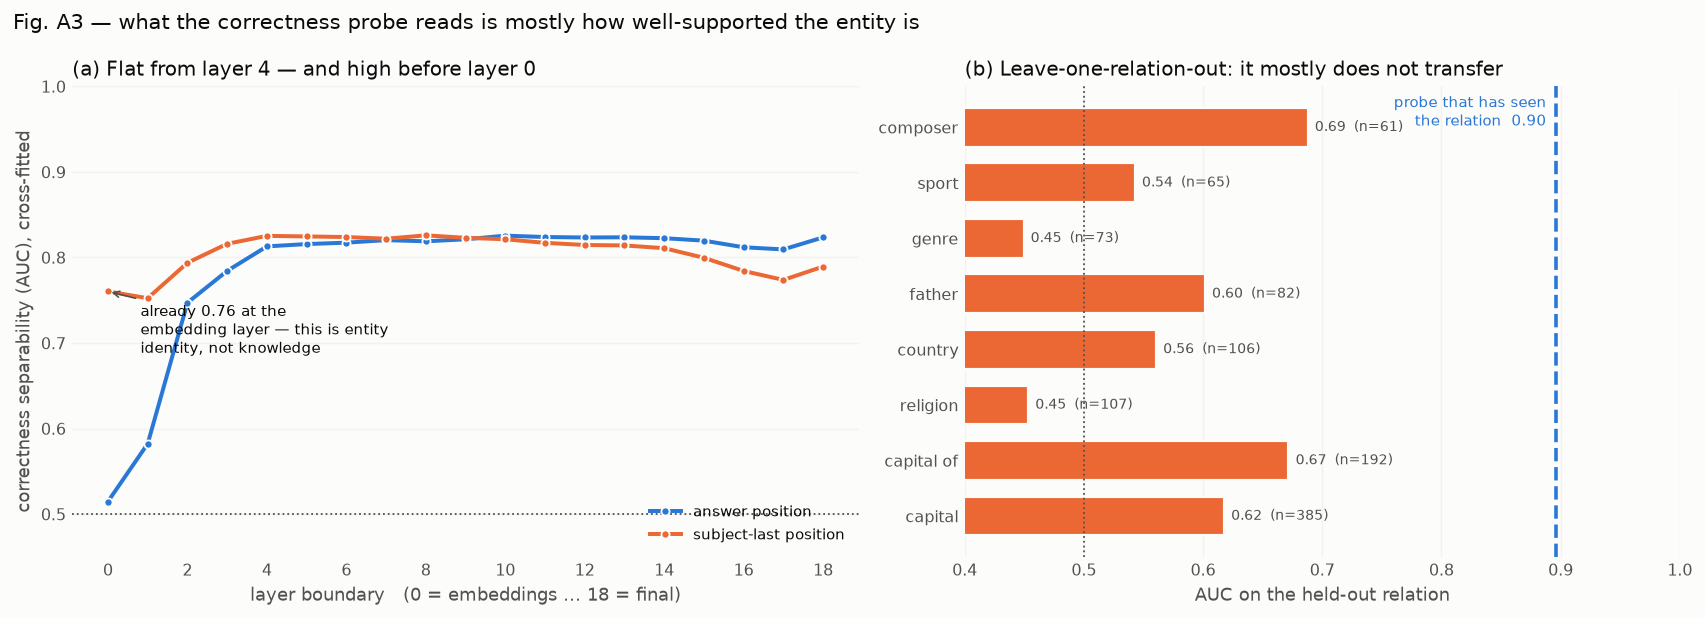

layer            :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
answer  (x-fit)  :  0.51  0.58  0.75  0.78  0.81  0.82  0.82  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.82  0.82  0.81  0.81  0.82
subject (x-fit)  :  0.76  0.75  0.79  0.82  0.83  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.81  0.81  0.81  0.80  0.78  0.77  0.79

checkpoint transfer: mean diagonal 0.896 vs mean off-diagonal 0.740
leave-one-relation-out mean AUC: 0.573 (range 0.45–0.69)


In [11]:
# ── Fig. A3 — cross-fitted separability, and leave-one-relation-out transfer  (hidden §9, §10) ──
HELD = FOLD == 0
probes = []
for i in range(n_t):
    tr = scoreable & ~HELD
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
    clf.fit(Hf_ans[i][tr], h_correct[tr, i])
    probes.append(clf)
te = scoreable & HELD
TRANS = np.full((n_t, n_t), np.nan)
for i in range(n_t):
    for j in range(n_t):
        if 0 < h_correct[te, j].mean() < 1:
            TRANS[i, j] = roc_auc_score(h_correct[te, j], probes[i].predict_proba(Hf_ans[j][te])[:, 1])

rel_counts = pd.Series(h_prop[scoreable]).value_counts()
loro = []
for r in rel_counts.index[:8]:
    te_r, tr_r = scoreable & (h_prop == r), scoreable & (h_prop != r)
    aucs_r = []
    for i in range(n_t):
        if not (0 < h_correct[te_r, i].mean() < 1):
            continue
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[i][tr_r], h_correct[tr_r, i])
        aucs_r.append(roc_auc_score(h_correct[te_r, i], c.predict_proba(Hf_ans[i][te_r])[:, 1]))
    loro.append((r, int(te_r.sum()), float(np.mean(aucs_r))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax1.plot(range(19), np.nanmean(sep_xf_ans, 0), color=BLUE, lw=2.2, marker="o", ms=4.5,
         mec=SURF, mew=1, label="answer position")
ax1.plot(range(19), np.nanmean(sep_xf_subj, 0), color=ORANGE, lw=2.2, marker="o", ms=4.5,
         mec=SURF, mew=1, label="subject-last position")
ax1.axhline(0.5, color=INK2, lw=1, ls=":")
ax1.annotate(f"already {np.nanmean(sep_xf_subj, 0)[0]:.2f} at the\nembedding layer — this is "
             "entity\nidentity, not knowledge",
             (0, np.nanmean(sep_xf_subj, 0)[0]), xytext=(18, -34), textcoords="offset points",
             fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="->", color=INK2, lw=.9))
ax1.set_xticks(range(0, 19, 2))
ax1.set_ylim(0.45, 1.0)
ax1.set_xlabel("layer boundary   (0 = embeddings … 18 = final)")
ax1.set_ylabel("correctness separability (AUC), cross-fitted")
ax1.set_title("(a) Flat from layer 4 — and high before layer 0", loc="left")
ax1.legend(loc="lower right", fontsize=8.5)

yb = np.arange(len(loro))
ax2.barh(yb, [v for _, _, v in loro], color=ORANGE, edgecolor=SURF, linewidth=1.2, height=.7)
diag = np.nanmean(np.diag(TRANS))
ax2.axvline(diag, color=BLUE, lw=2, ls="--")
ax2.text(diag - .008, len(loro) - .4, f"probe that has seen\nthe relation  {diag:.2f}",
         ha="right", va="top", fontsize=8.5, color=BLUE)
ax2.axvline(0.5, color=INK2, ls=":", lw=1)
for i, (_, n_, v) in enumerate(loro):
    ax2.text(v + .006, i, f"{v:.2f}  (n={n_})", va="center", fontsize=8, color=INK2)
ax2.set_yticks(yb, [r for r, _, _ in loro], fontsize=9)
ax2.set_xlim(0.4, 1.0)
ax2.set_xlabel("AUC on the held-out relation")
ax2.set_title("(b) Leave-one-relation-out: it mostly does not transfer", loc="left")

clean(ax1); clean(ax2, axis="x")
fig.suptitle("Fig. A3 — what the correctness probe reads is mostly how well-supported the "
             "entity is", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("layer            :", " ".join(f"{i:5d}" for i in range(19)))
print("answer  (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_ans, 0)))
print("subject (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_subj, 0)))
off = TRANS[~np.eye(n_t, dtype=bool)]
print(f"\ncheckpoint transfer: mean diagonal {diag:.3f} vs mean off-diagonal {np.nanmean(off):.3f}")
print(f"leave-one-relation-out mean AUC: {np.mean([v for _, _, v in loro]):.3f} "
      f"(range {min(v for _, _, v in loro):.2f}–{max(v for _, _, v in loro):.2f})")

**Result.** The subject position is separable at **AUC ≈ 0.76 in the embedding layer**, before
any block has run, and held-out-relation transfer averages ≈**0.57** against ≈0.90 for a probe
that has seen the relation — with the weakest relations at or below chance. So most of the
apparent "correctness is linearly legible in the residual stream" is the probe learning **which
relations and entities tend to be answered correctly**, which is exactly the confound Hewitt &
Liang designed control tasks for and which Mallen et al. would predict from entity popularity.

The honest restatement: *the residual stream linearly encodes how well-supported this
entity/relation is, which strongly predicts recall. There is a residual, relation-specific "do I
know this particular fact" component, but it is much smaller than the within-relation AUC of
0.90 suggests.*

Two consequences to carry into the text. Figure 3a's 51% is an **upper bound**, because
entity/relation identity does not change between adjacent checkpoints and the probe reads it
either way. And the natural repair — recomputing the knowledge direction *within* each relation
— needs no new data, only the existing hidden states.

---
## Figure A4 — neuron-mates share a fate; nothing takes turns

**Source:** `forgetting_internal_features.ipynb` §20 (with the §21 k-sensitivity summarised in
the text).
**Papers:** McCloskey & Cohen (1989), *Catastrophic Interference*; French (1999); Elhage et al.
(2022), *Toy Models of Superposition*; Kotha et al. (2024).

**Why the appendix.** The frequency notebook ends on one loose thread: of every frequency-like
variable, **only competition** — the number of other facts sharing a subject's competitive word
— *raises* the forgetting hazard. The obvious mechanism is the classical one. French (1999)
states it as sharply as it can be stated: catastrophic interference is caused by
**representational overlap**. Translated here: two facts on the same mid-stack neurons should
take turns — one right when the other is wrong.

The neuron dump tests it directly, twice.

**(a) Do neuron-mates' trajectories anti-correlate?** Correlate two facts' correctness
trajectories after removing each fact's own mean (how often it is right) and each checkpoint's
mean (the global accuracy curve), and plot against their shared-neuron count. Competition
predicts the curve goes **down**, below zero. Because relations learn as blocks and relations
share neurons, a second version also removes each relation's own trajectory.

**(b) What do a fact's neuron-mates do at the exact moment it flips?** For every event, take the
fact's 20 *most*-overlapping partners **from other relations** and its 20 *least*-overlapping
ones. Near and far are compared inside the same event, at the same checkpoint, across the same
relation boundary — the only thing that differs is the overlap. Competition predicts the near
group *learns* while the fact is lost; interference predicts the near group is *also* lost.
These are different cells of the 2 × 2 and cannot both be true.

overlap matrix in 8s


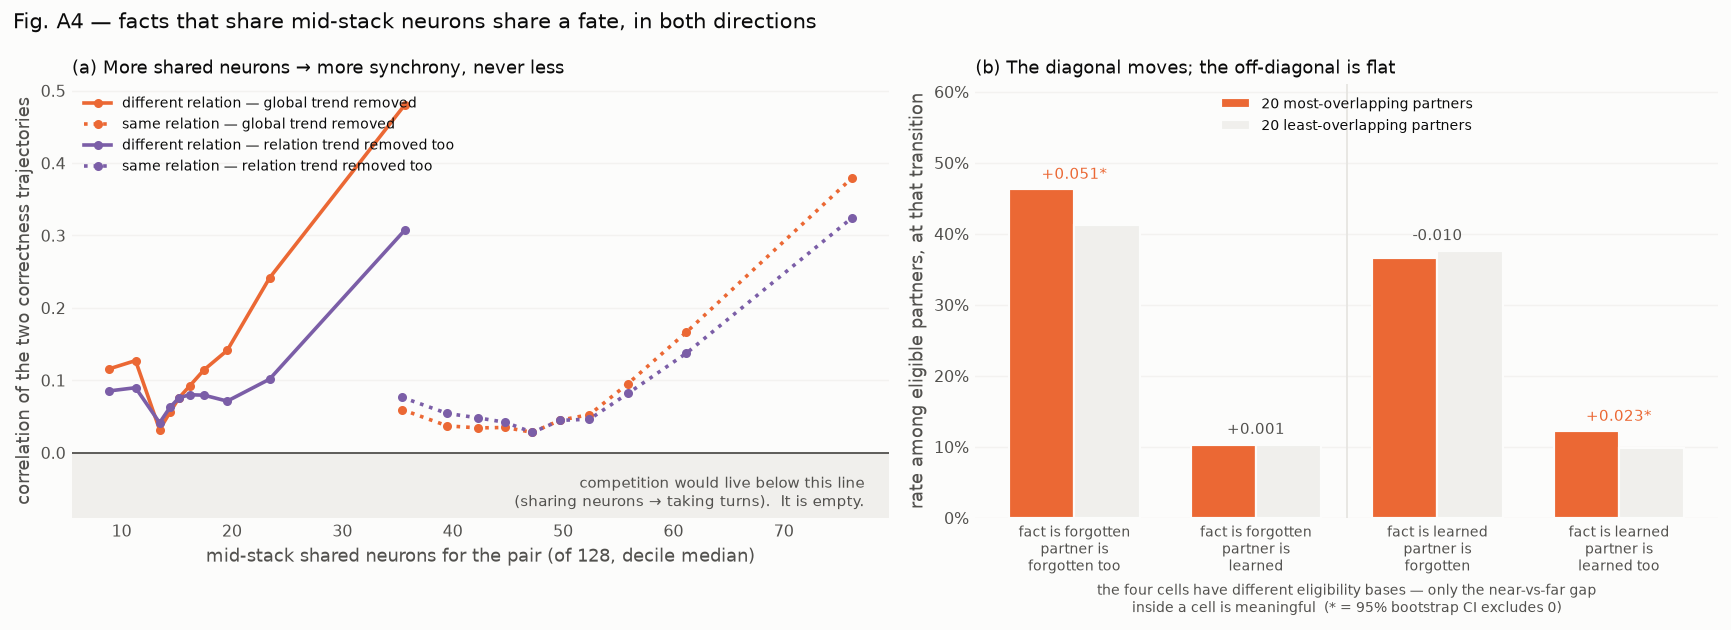

rho(shared neurons, co-fluctuation), global trend removed:
    same relation        +0.1354
    different relation   +0.1487
rho(shared neurons, co-fluctuation), relation trend removed too:


    same relation        +0.0840
    different relation   +0.0969

mid-stack shared neurons out of 128: same relation 50.8  different relation 18.1  (2.81x)

nearest vs farthest cross-relation partners (overlap 37.5 vs 9.5 shared neurons):
  fact forgotten -> partner is forgotten too near 0.462  far 0.412   diff +0.051 [+0.017, +0.091]
  fact forgotten -> partner is learned     near 0.103  far 0.102   diff +0.001 [-0.009, +0.011]
  fact learned   -> partner is forgotten   near 0.366  far 0.376   diff -0.010 [-0.039, +0.017]
  fact learned   -> partner is learned too near 0.122  far 0.099   diff +0.023 [+0.013, +0.031]


In [12]:
# ── Fig. A4 — do neuron-sharing facts compete, or move together?  (internal §20) ──────
import scipy.sparse as sp

# Mid-stack fact x fact overlap.  One sparse incidence matrix B[fact, neuron] per
# (checkpoint, layer); B @ B.T gives every pair's shared-neuron count in one product, which is
# far cheaper than 858 000 pairwise set intersections.
_t0 = time.time()
OV = np.zeros((len(ids), len(ids)), np.float32)
_rows = np.repeat(np.arange(len(ids)), K_NEU)
MID_L = list(range(MID.start, MID.stop))
for s in steps:
    I = _load(s, "answer", "idx").astype(np.int32)
    for l in MID_L:
        B = sp.csr_matrix((np.ones(_rows.size, np.float32), (_rows, I[:, l, :].ravel())),
                          shape=(len(ids), N_INTER))
        B.data[:] = 1.0                        # a neuron can repeat in a row only via the csr
        OV += (B @ B.T).toarray()              # sum; force binary before the product
OV /= n_steps * len(MID_L)
np.fill_diagonal(OV, np.nan)                   # a fact always shares 128 with itself
print(f"overlap matrix in {time.time() - _t0:.0f}s")

same_prop = prop[:, None] == prop[None, :]
_iu = np.triu_indices(len(ids), 1)
ov_pair, pair_same_prop = OV[_iu], same_prop[_iu]

def cofluctuation(demean_relation):
    """Pearson correlation of two facts' correctness trajectories after removing the per-fact
    mean (how often it is right) and the per-checkpoint mean (the global accuracy curve).  With
    `demean_relation`, each relation's own trajectory goes too, so a relation learning as a
    block cannot manufacture the effect."""
    X = correct.astype(np.float32).copy()
    if demean_relation:
        for p in np.unique(prop):
            m = prop == p
            X[m] -= X[m].mean(0, keepdims=True)
    X = X - X.mean(1, keepdims=True) - X.mean(0, keepdims=True) + X.mean()
    sd = X.std(1); a = sd > 1e-6
    Z = np.zeros_like(X); Z[a] = X[a] / sd[a][:, None]
    return ((Z @ Z.T) / n_steps)[_iu], (a[:, None] & a[None, :])[_iu]

cof_glob, pair_ok = cofluctuation(False)
cof_rel, _ = cofluctuation(True)

NBR_M = 20
_Ox = np.where(same_prop | np.isnan(OV), np.nan, OV)        # cross-relation partners only
nbr_near = np.argsort(np.nan_to_num(_Ox, nan=-1), 1)[:, ::-1][:, :NBR_M]
nbr_far = np.argsort(np.nan_to_num(_Ox, nan=1e9), 1)[:, :NBR_M]
ev_learn = (~correct[:, :-1]) & correct[:, 1:]
ev_forget = correct[:, :-1] & (~correct[:, 1:])

def neighbour_rate(event, NB, outcome):
    """Rate of `outcome` among a fact's partners at the very transition where the fact itself
    had `event`.  Only partners *eligible* for the outcome count (a fact can be forgotten only
    if it is currently correct)."""
    out = []
    for t in range(n_steps - 1):
        elig = correct[:, t] if outcome is ev_forget else ~correct[:, t]
        for f in np.where(event[:, t])[0]:
            g = NB[f][elig[NB[f]]]
            if len(g):
                out.append(outcome[g, t].mean())
    return np.array(out)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9), gridspec_kw={"width_ratios": [1.1, 1]})
for cof, col, lab in ((cof_glob, ORANGE, "global trend removed"),
                      (cof_rel, PURPLE, "relation trend removed too")):
    for m, ls, tag in ((pair_ok & ~pair_same_prop, "-", "different relation"),
                       (pair_ok & pair_same_prop, ":", "same relation")):
        q = pd.qcut(ov_pair[m], 10, labels=False, duplicates="drop")
        x = [np.median(ov_pair[m][q == i]) for i in range(q.max() + 1)]
        y = [cof[m][q == i].mean() for i in range(q.max() + 1)]
        ax1.plot(x, y, color=col, lw=2, ls=ls, marker="o", ms=4, label=f"{tag} — {lab}")
ax1.axhspan(-.09, 0, color=NEUTRAL, zorder=0)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_ylim(-.09, None)
ax1.annotate("competition would live below this line\n(sharing neurons → taking turns).  It is empty.",
             (0.97, 0.015), xycoords="axes fraction", fontsize=8.5, color=INK2, va="bottom", ha="right")
ax1.set_xlabel(f"mid-stack shared neurons for the pair (of {K_NEU}, decile median)")
ax1.set_ylabel("correlation of the two correctness trajectories")
ax1.set_title("(a) More shared neurons → more synchrony, never less", loc="left", fontsize=10)
ax1.legend(loc="upper left", fontsize=7.5)

CASES = [("forgotten", ev_forget, ev_forget, "partner is\nforgotten too"),
         ("forgotten", ev_forget, ev_learn, "partner is\nlearned"),
         ("learned", ev_learn, ev_forget, "partner is\nforgotten"),
         ("learned", ev_learn, ev_learn, "partner is\nlearned too")]
rng = np.random.default_rng(0)
near_v, far_v, cis = [], [], []
for _, ev, out, _lab in CASES:
    a, b = neighbour_rate(ev, nbr_near, out), neighbour_rate(ev, nbr_far, out)
    near_v.append(a.mean()); far_v.append(b.mean())
    boot = [rng.choice(a, a.size).mean() - rng.choice(b, b.size).mean() for _ in range(400)]
    cis.append(np.percentile(boot, [2.5, 97.5]))
xg = np.arange(4); w = .36
ax2.bar(xg - w/2, near_v, w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} most-overlapping partners")
ax2.bar(xg + w/2, far_v, w, color=NEUTRAL, edgecolor=SURF, linewidth=1.2,
        label=f"{NBR_M} least-overlapping partners")
for i, (a, b, (lo, hi)) in enumerate(zip(near_v, far_v, cis)):
    sig = "" if lo < 0 < hi else "*"
    ax2.text(i, max(a, b) + .015, f"{a - b:+.3f}{sig}", ha="center", fontsize=8.5,
             color=INK2 if not sig else ORANGE)
ax2.set_xticks(xg, [f"fact is {c[0]}\n{c[3]}" for c in CASES], fontsize=7.5)
ax2.axvline(1.5, color=GRID, lw=1)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("rate among eligible partners, at that transition")
ax2.set_ylim(0, max(near_v + far_v) * 1.32)
ax2.set_title("(b) The diagonal moves; the off-diagonal is flat", loc="left", fontsize=10)
ax2.set_xlabel("the four cells have different eligibility bases — only the near-vs-far gap\n"
               "inside a cell is meaningful  (* = 95% bootstrap CI excludes 0)", fontsize=8)
ax2.legend(loc="upper center", fontsize=8)

clean(ax1); clean(ax2)
fig.suptitle("Fig. A4 — facts that share mid-stack neurons share a fate, in both directions",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

for nm, cof in (("global trend removed", cof_glob), ("relation trend removed too", cof_rel)):
    print(f"rho(shared neurons, co-fluctuation), {nm}:")
    for lab, m in (("same relation", pair_ok & pair_same_prop),
                   ("different relation", pair_ok & ~pair_same_prop)):
        print(f"    {lab:20s} {spearmanr(ov_pair[m], cof[m])[0]:+.4f}")
print(f"\nmid-stack shared neurons out of {K_NEU}: same relation "
      f"{np.nanmean(ov_pair[pair_same_prop]):.1f}  different relation "
      f"{np.nanmean(ov_pair[~pair_same_prop]):.1f}  "
      f"({np.nanmean(ov_pair[pair_same_prop]) / np.nanmean(ov_pair[~pair_same_prop]):.2f}x)")
print(f"\nnearest vs farthest cross-relation partners (overlap "
      f"{np.nanmean(np.take_along_axis(_Ox, nbr_near, 1)):.1f} vs "
      f"{np.nanmean(np.take_along_axis(_Ox, nbr_far, 1)):.1f} shared neurons):")
for (evn, _, _, out_lab), a, b, (lo, hi) in zip(CASES, near_v, far_v, cis):
    print(f"  fact {evn:9s} -> {out_lab.replace(chr(10), ' '):22s} "
          f"near {a:.3f}  far {b:.3f}   diff {a - b:+.3f} [{lo:+.3f}, {hi:+.3f}]")

**Result — there is no competition anywhere in this data.**

Test (a) points the wrong way for the interference hypothesis, and monotonically: among
cross-relation pairs, correctness correlation climbs from ≈+0.12 in the lowest overlap decile to
≈+0.48 in the highest. Removing each relation's own trajectory halves the slope but does not
touch the sign. The region below zero — where every form of interference would have to live —
is **empty at every overlap level**.

Test (b) is the clean one, and gives a 2 × 2 with two significant cells and two null cells, all
four in the same direction. A fact's closest cross-relation neuron-mates are significantly more
likely to be forgotten *with* it (+0.05) and learned *with* it (+0.02); they are no more likely
to be learned when it is lost, or lost when it is learned. Zero-sum competition would require
exactly those two null cells to be the significant ones.

**What this means.** French's overlap→interference prediction does not transfer to factual
recall in a pretraining LM at this resolution. Overlap here marks facts the model processes with
the *same machinery*, and shared machinery means a shared response to whatever the next 50k
steps do to it. The mid-stack behaves like a shared circuit being retuned, not like a contested
resource — which also re-reads the competition variable from the frequency notebook: a subject
whose token is shared by many facts gets a *less discriminative* representation, so its facts
are all weakly stored, and being weakly stored together they wobble together. That is a failure
of the key, not a battle over the value.

**Robustness worth one sentence in the text.** Re-running the whole test at k ∈ {8, 16, 32, 64,
128} leaves the null intact at every k — including k = 8, where the analysis sees only each
fact's eight most active neurons — once the small-k composition offset is removed with a
difference-in-differences. There is no contested core hiding under a synchronised tail. The one
limit that remains is temporal, not spatial: interference that resolves inside a single 50k-step
interval is invisible at any k.

---
## Figure A5 — a noise floor: is "forgetting" just a stochastic read-out?

**Source:** `forgetting_internal_features.ipynb` §10.
**Papers:** Toneva et al. (2019) (the *unforgettable examples* baseline); Maini et al. (2022),
*Second-Split Forgetting*.

**Why the appendix.** This is the test the entire project most needs, because every fragility
result is vulnerable to one deflationary reading. `correct` is a lenient substring match on a
greedy generation. If correctness were simply a **noisy sample** from the model's answer
distribution, then low-gold-probability facts would flip back and forth *by construction*, and
"forgetting strikes fragile facts" would be a restatement of "a coin weighted 0.1 comes up tails
a lot" — no learning dynamics required.

The null makes that precise. Calibrate P(correct | gold probability) on all (fact, checkpoint)
observations, then **resample every observation independently** from that calibration, keeping
each fact's real gold-probability trajectory. The null has, by construction, the same
relationship between confidence and correctness as the real data — it differs *only* in having
no memory from one checkpoint to the next. Comparing the resulting **dynamics** isolates exactly
what the scalar cannot explain.

It goes in the appendix rather than the body because it establishes that there is something to
explain, not what the explanation is.

calibration AUC (gold_prob -> correct): 0.757


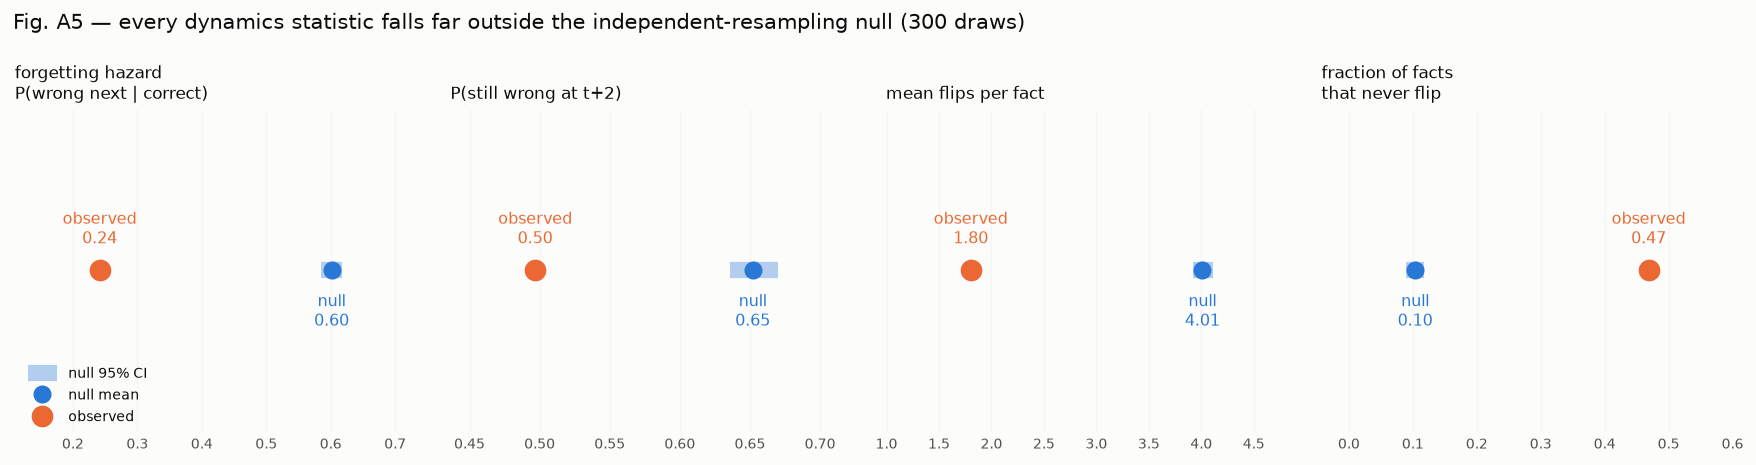


                                observed  null mean          null 95% CI
hazard                             0.241      0.601   [0.586, 0.617]
P(still wrong t+2)                 0.497      0.652   [0.635, 0.670]
mean flips/fact                    1.802      4.010   [3.918, 4.112]
frac never flipping                0.469      0.104   [0.090, 0.118]


In [13]:
# ── Fig. A5 — the noise-floor null  (internal §10) ────────────────────────────────────
gp_mat = NEWP["gold_prob"]
lp = np.log10(np.clip(gp_mat, 1e-9, 1))
obsm = np.isfinite(lp)
Xc = np.column_stack([lp[obsm], lp[obsm] ** 2])
cal = LogisticRegression(max_iter=1000).fit(Xc, correct[obsm])
phat = np.zeros_like(gp_mat)
phat[obsm] = cal.predict_proba(Xc)[:, 1]
print(f"calibration AUC (gold_prob -> correct): {roc_auc_score(correct[obsm], phat[obsm]):.3f}")

def dynamics(C):
    """Four summaries of the *temporal* structure of a correctness matrix."""
    haz = (C[:, :-1] & ~C[:, 1:]).sum() / max(C[:, :-1].sum(), 1)
    pers = [~C[C[:, t] & ~C[:, t + 1], t + 2] for t in range(n_steps - 2)
            if (C[:, t] & ~C[:, t + 1]).any()]
    flips = (C[:, 1:] != C[:, :-1]).sum(1)
    return haz, np.mean(np.concatenate(pers)), flips.mean(), (flips == 0).mean()

rng = np.random.default_rng(0)
observed = dynamics(correct)
null = np.array([dynamics(rng.random(gp_mat.shape) < phat) for _ in range(300)])

LABELS = ["forgetting hazard\nP(wrong next | correct)", "P(still wrong at t+2)",
          "mean flips per fact", "fraction of facts\nthat never flip"]
# The null is extremely tight, so a histogram renders as a hairline: show each metric as
# observed vs null-mean dots with the null 95% CI drawn as a bar.
fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.6))
for i, (ax, lab) in enumerate(zip(axes, LABELS)):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    ax.hlines(0, lo_n, hi_n, color=BLUE, lw=9, alpha=.35, zorder=1, label="null 95% CI")
    ax.plot(null[:, i].mean(), 0, "o", color=BLUE, ms=9, zorder=2, label="null mean")
    ax.plot(observed[i], 0, "o", color=ORANGE, ms=11, zorder=3, label="observed")
    lo_x, hi_x = min(observed[i], lo_n), max(observed[i], hi_n)
    pad = (hi_x - lo_x) * 0.35 + 1e-6
    ax.set_xlim(lo_x - pad, hi_x + pad)
    ax.annotate(f"observed\n{observed[i]:.2f}", (observed[i], 0), color=ORANGE, fontsize=9,
                ha="center", va="bottom", xytext=(0, 12), textcoords="offset points")
    ax.annotate(f"null\n{null[:, i].mean():.2f}", (null[:, i].mean(), 0), color=BLUE, fontsize=9,
                ha="center", va="top", xytext=(0, -12), textcoords="offset points")
    ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.set_title(lab, loc="left", fontsize=9.5)
    ax.tick_params(length=0, labelsize=8); ax.grid(axis="x", alpha=.3)
    for s_ in ax.spines.values():
        s_.set_visible(False)
axes[0].legend(loc="lower left", fontsize=8, bbox_to_anchor=(0, -0.02))
fig.suptitle("Fig. A5 — every dynamics statistic falls far outside the independent-resampling "
             "null (300 draws)", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"\n{'':30s} {'observed':>9s} {'null mean':>10s} {'null 95% CI':>20s}")
for i, lab in enumerate(["hazard", "P(still wrong t+2)", "mean flips/fact", "frac never flipping"]):
    lo_n, hi_n = np.percentile(null[:, i], [2.5, 97.5])
    print(f"{lab:30s} {observed[i]:9.3f} {null[:, i].mean():10.3f}   [{lo_n:.3f}, {hi_n:.3f}]")

**Result — the deflationary reading is decisively rejected, in the direction that strengthens
the thesis.** The null reproduces the confidence ↔ correctness relationship exactly (calibration
AUC 0.757) but has no memory across checkpoints, and its dynamics are nothing like the observed
ones. Real correctness is **≈2.2× more persistent** than an independent read-out of the same
gold probabilities would be, and ≈47% of facts never flip at all against a null expectation of
≈10% — a direct analogue of Toneva et al.'s *unforgettable examples*.

Two consequences, and the second is why the body figures exist. (1) "Forgetting strikes fragile
facts" survives — it is not an artefact of stochastic scoring. (2) But the same result says gold
probability is a **badly incomplete** description of a fact's state, which is precisely why the
neuron features in Figure 2 can beat it, and why Figure 1's mid-stack signal exists at all. This
figure is the proof *by elimination* that a fact carries state the output scalar misses;
Figure 2 is the positive counterpart that names part of it.

---
# Summary — what the eight figures say together

**Body.**

1. **Where.** Forgetting is a mid-stack failure. Survivors and soon-to-be-forgotten facts are
   indistinguishable through boundary 7 and diverge by an order of magnitude in gold rank at
   boundary 12 — the shape of an *attribute-extraction* failure, not a read-out failure.
2. **When, and how well can it be seen coming.** The fact's neuron set was already churning
   during the *previous* interval, deepest at the same layer, and ten summaries of the neuron
   dump predict the next flip better than every output scalar combined (0.711 vs 0.680; 0.739
   together).
3. **What kind of event.** Half of what the model stops saying it has not stopped representing
   (51% vs a 73% control vs 0% observed); 44% of flips are competitor takeovers rather than
   decay, and half of all flips reverse within one checkpoint.

**Appendix.** A1 derives the mid-stack band the body figures assume. A2 shows one CV choice
turned a 0.70 probe into a 0.48 one and re-scores every predictor leak-free. A3 shows the
correctness direction is largely entity/relation identity, which bounds every probe number
including Figure 3a's. A4 rules out interference between neuron-mates — they share a fate rather
than competing. A5 rules out the stochastic-scoring account of the whole phenomenon.

**The through-line.** Forgetting in LMEnt is neither erasure nor a contest. It is a **shared
mid-stack circuit being continuously retuned**, with each fact's survival depending on how
sharply and how privately it happens to be written into that circuit at the moment. That is why
weak storage predicts loss, why churn predicts it better, why neuron-mates rise and fall
together — and, with the frequency notebook, why evidence for a fact is the strongest protection
against losing it.

**What is deliberately not here.** The frequency/hazard results (their own notebook), the fact
cartography and per-relation hazard tables (descriptive, superseded), the relation-geography and
k-sensitivity panels (robustness, better as text), and the event-aligned scalar curves
(subsumed by Figure 1).